# Sesi 5 — NusaMart | Membangun Pipeline Multi Sumber (Bagian 1)
### STARTER NOTEBOOK · Practice in Class · Panduan Peserta

> **Misi bisnis:** Tim NusaMart perlu menggabungkan enam sumber penjualan menjadi **satu baris per pesanan**. Sebelum hasilnya dapat digunakan untuk dashboard/analisis, analis harus membuktikan bahwa order, nilai penjualan, dan pembayaran **tidak terhitung dua kali**.

**Peran kamu:** Junior Data Analyst yang menggunakan **Antigravity (AI Agent) sebagai asisten kerja**, bukan penentu kebenaran. Kamu mengarahkan Agent, memeriksa rencana/kode, membaca bukti, dan mengambil keputusan.

**Dua output resmi yang tidak berubah:**
1. **Draf Pipeline Penggabungan 6 Sumber Data Fiktif** — Notebook ini yang sudah memuat implementasi dan validasi 7A–7D, bukan CSV saja.
2. **Draf Data Dictionary** — Working Paper, sheet `04_Data_Dictionary`, minimal 12 field aktual yang ditelusuri asalnya.

**Evidence pendukung:** Sheet 01 (inventaris), Sheet 02 (Join Plan), Sheet 03 (validasi), CSV hasil integrasi, dan hasil pemeriksaan. Evidence pendukung bukan output resmi ketiga.

**Penting:** Dataset S5 adalah **training extract baru** NusaMart, **bukan ekspor langsung** hasil praktik S3 atau S4. Pakai enam source S5 yang disediakan, **jangan menimpa raw data**, jangan meminta PII mentah.

### Cara belajar untuk peserta yang baru mengenal Python dan SQL
- Tombol ▶ atau `Shift+Enter` menjalankan **satu cell**. **Jangan gunakan Run All** untuk melewati TODO Section 7; bagian 7A–7D adalah implementasi dibantu Antigravity.
- Baris dengan `#` adalah komentar, bukan perintah yang harus diketik.
- `DataFrame` adalah **tabel data sementara** di Notebook; `rows × columns` berarti jumlah baris dan kolom.
- `groupby` = mengelompokkan data; `SUM` = menjumlahkan; `LEFT JOIN` = mempertahankan semua data dari tabel sebelah kiri.
- **PASS** = lulus berdasarkan bukti; **FAIL** pada naive join = kesalahan yang sengaja didemonstrasikan; **PENDING** = belum dikerjakan; **HOLD** = jangan terima/ekspor sebelum diperbaiki.

### Pola tiap Praktik
**CASE → TUJUAN → PAHAMI → LIHAT CONTOH → COBA → BACA OUTPUT → INTERPRETASI → JUDGMENT → ISI WORKING PAPER → CHECKPOINT → LANJUT.**

Selesaikan setiap tanda **⏸ STOP** sebelum lanjut. **Jangan memilih PASS hanya karena kode berjalan**. Bilangan yang ditulis ke Working Paper harus diambil dari output Notebook masing-masing.

> **Acuan file:** `S5_NusaMart_Integration_Starter.ipynb` (Notebook ini) dan Working Paper S5 pada sheet `01_Source_Inventory`, `02_Join_Plan`, `03_Validation_Evidence`, `04_Data_Dictionary`. Nama tanpa label versi.

## Peta perjalanan bisnis NusaMart — 5 Praktik yang saling terhubung

| Praktik | Mini-case bisnis | Section Notebook | Kapan isi Working Paper? | Hasil/judgment |
|---|---|---|---|---|
| **1. Inventarisasi** | Manajer menerima 6 file dari beberapa divisi | **0–2** dan verifikasi key **3** | Sheet 01 baris 7–12 setelah membaca source, finalkan setelah key check | 6 sumber dikenali, tidak join terburu-buru |
| **2. Rencanakan join** | Manajer meminta **1 row/order** | **3–4** | Sheet 02 JP-01–JP-05, Sheet 03 VE-01–03 | Grain, key, dan baseline disetujui |
| **3. Temukan fan trap** | Setelah join langsung, omzet tampak melonjak | **5–6** | Sheet 03 VE-04–06 dan Fan Trap baris 21 | Naive join FAIL (disengaja); bukti ditemukan |
| **4. Perbaiki dengan Agent** | Data siap digunakan hanya bila angka benar | **7A–9** | Sheet 02 review keputusan; Sheet 03 VE-07–11 dan Unmatched 26–30 | Corrected pipeline PASS/HOLD berdasar bukti |
| **5. Jelaskan datanya** | Analis lain harus memahami arti hasil pipeline | **10** | Sheet 04 minimal 12 field, baris 7–36 | Draf Data Dictionary terdokumentasi |

### Source yang disiapkan (target referensi S5)

| Sumber | Format fisik | Jumlah baris referensi | Grain awal |
|---|---|---:|---|
| Orders | CSV | 320 | Satu baris per order |
| Order Items | Parquet | 760 | Satu baris per item dalam order |
| Customers Safe | XLSX | 215 | Satu baris per pelanggan aman |
| Payments | SQLite | 337 | Satu baris per pembayaran |
| Products | JSON | 45 | Satu baris per produk |
| Channel/Campaign | Google Sheets/CSV seed | 300 | Satu mapping per order |

**Baseline bisnis referensi:** 320 order unik, Rp42.061.000 pada `order_total`, dan Rp42.061.000 pada sumber pembayaran. Angka referensi untuk pengecekan **bukan angka yang boleh disalin tanpa menjalankan Notebook**.

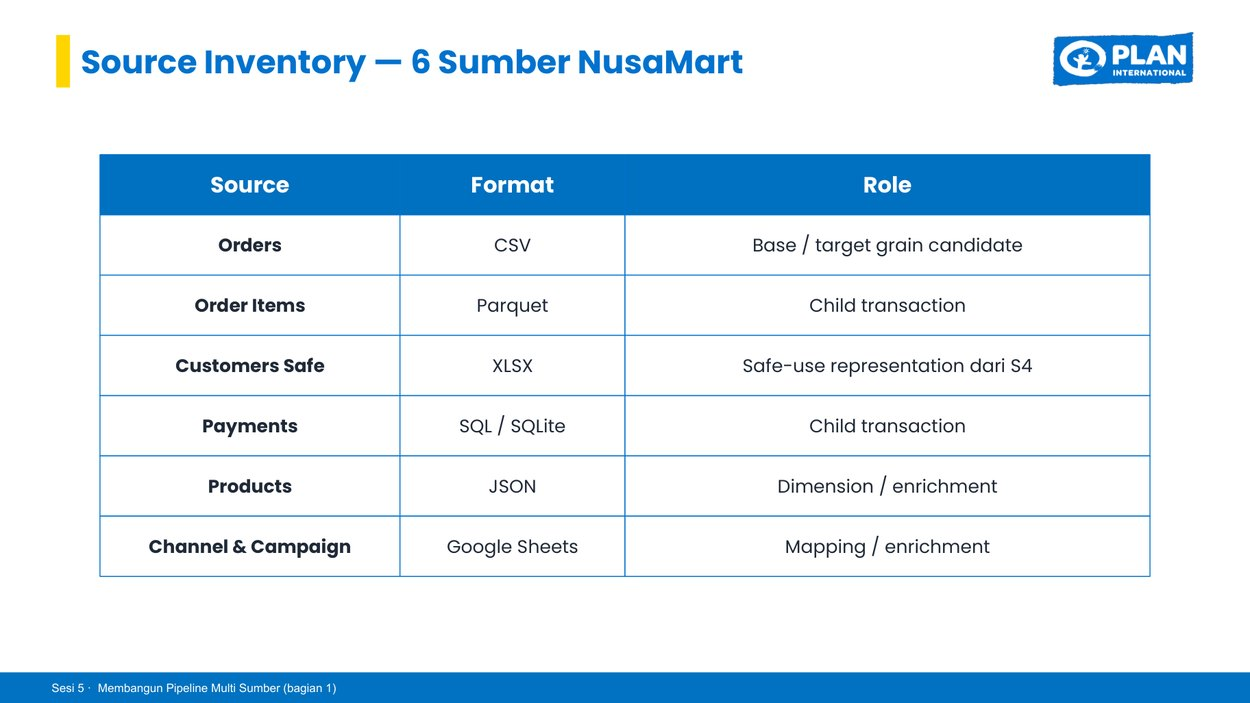

*Enam sumber dengan fungsi berbeda. Jangan langsung digabung sebelum memahami grain-nya. — visual bersumber dari **PPT S5 halaman 10**, bukan screenshot hasil RUN Notebook.*

---
# PRAKTIK 1 — Enam sumber NusaMart datang: apakah semuanya siap digunakan?

**CASE:** Divisi Penjualan, Produk, Pelanggan, Keuangan, dan Pemasaran mengirimkan data dalam format berbeda. Manajer meminta digabungkan menjadi satu laporan. Kamu diminta **memeriksa bahan sebelum mengolahnya**.

**TUJUAN:** mengidentifikasi keenam file, memahami fungsi serta jumlah baris, dan memastikan sumber pelanggan aman digunakan. **Jangan join pada praktik ini.**

**PAHAMI:** Source Inventory ibarat daftar paket yang diterima. Nama file/format menunjukkan *bungkusnya*, grain menjelaskan *satu baris mewakili apa*, key menjelaskan *identitas data*, dan safe-use menjelaskan *batas pemakaiannya*.

**LIHAT CONTOH (referensi):** `Orders 320 rows × 5 columns` artinya 320 baris pesanan dengan 5 kolom, **bukan** 320 pelanggan. `LOCAL FALLBACK` artinya memakai CSV seed, bukan koneksi Google Sheets live yang berhasil diverifikasi.

**LANGKAH:** Section 0 cek lingkungan/file → Section 1 baca source → Section 2 lihat Source Inventory → mulai isi Sheet 01 → Section 3 lengkapi key dan review. Setelah itu lanjut Praktik 2.

## Section 0 — Siapkan Workspace dan Periksa Tools

**Analogi:** Sebelum memasak dari enam bahan, pastikan semua bahan ada di meja. Kita tidak mulai memasak kalau tepung atau airnya belum ada.

### Yang peserta lakukan

1. Unduh dan ekstrak **paket dataset S5** ke workspace. Folder enam sumber seharusnya `practice/sesi_05/source/`.
2. Buka Notebook ini menggunakan **Jupyter / VS Code / Antigravity** pada workspace yang sama.
3. Jalankan cell berikut dengan tombol ▶ **Run** (atau `Shift+Enter`).
4. Bacalah status `ENVIRONMENT CHECK` dan `SOURCE FOLDER`.

**File yang harus ada:** `nusamart_orders_s5.csv`, `nusamart_order_items_s5.parquet`, `nusamart_customers_safe_s5.xlsx`, `nusamart_payments_s5.sqlite`, `nusamart_products_s5.json`, dan `channel_campaign_google_sheets_seed.csv` (fallback).

> **Jika library belum ada:** Jalankan `%pip install pyarrow openpyxl` di **cell baru**, restart kernel jika diperlukan, lalu mulai lagi dari Section 0. *Jangan mengetik* `%pip install` di tengah kode Python lain.

> **Jika folder tidak ditemukan:** cek apakah ada folder pembungkus dobel, contohnya `source/S5_NusaMart_Multi_Source_Practice/...`. Enam file harus berada langsung pada folder yang dicari. Pilihan lanjut: isi `SOURCE_DIR_OVERRIDE` dengan folder lokasi keenam file jika workspace berbeda.

In [1]:
%pip install pyarrow openpyxl

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/28.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/28.5 MB ? eta -:--:--
    --------------------------------------- 0.5/28.5 MB 1.5 MB/s eta 0:00:19
   - -------------------------------------- 0.8/28.5 MB 1.4 MB/s eta 0:00:20
   -- ------------------------------------- 1.6/28.5 MB 2.0 MB/s eta 0:00:14
   -- ------------------------------------- 2.1/28.5 MB 2.1 MB/s eta 0:00:13
   --- ------------------------------------ 2.6/28.5 MB 2.1 MB/s eta 0:00:13
   ---- ----------------------------------- 3.1/28.5 MB 2.3 MB/s eta 0:00:12
   ---- ----------------------------------- 3.4/28.5 MB 2.2 MB/s eta 0:00:12
   ----- ---------------------------------- 3.9/28.5 MB 2.1 MB/s eta 0:00:12
   ----- ---------------------------------- 4.2/28.5 MB 2.0 MB/s eta 0:00:13
   ------ --------------------------------- 4.5/28.5 MB 2.0 MB/s eta 0:00:12
   ------ --


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\lucih\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import sqlite3
import importlib.util
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

# --- Opsional. Biarkan kosong jika folder mengikuti panduan. ---
SOURCE_DIR_OVERRIDE = ""  # contoh: r"C:\Users\...\practice\sesi_05\source"

# Kosong = gunakan seed CSV lokal (FALLBACK, BUKAN akses Google Sheets live).
# Bila trainer sudah memberi URL publik yang benar, isi URL CSV export Google Sheets.
GOOGLE_SHEET_CSV_URL = ""

required_packages = {"pyarrow": "membaca Parquet", "openpyxl": "membaca XLSX"}
missing = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(
        "Library belum tersedia: " + ", ".join(missing)
        + ". Buat cell BARU: %pip install " + " ".join(missing)
        + " ; restart kernel bila perlu, kemudian Run Section 0 ulang."
    )
print("ENVIRONMENT CHECK: PASS")

SOURCE_DIR = None
if SOURCE_DIR_OVERRIDE.strip():
    candidate = Path(SOURCE_DIR_OVERRIDE).expanduser()
    if candidate.is_dir():
        SOURCE_DIR = candidate.resolve()
    else:
        raise FileNotFoundError(f"Folder pada SOURCE_DIR_OVERRIDE tidak ada: {candidate}")
else:
    current = Path.cwd().resolve()
    for base in [current, *current.parents]:
        for relative in [Path("practice/sesi_05/source"), Path("S5_NusaMart_Multi_Source_Practice")]:
            candidate = base / relative
            if candidate.is_dir():
                SOURCE_DIR = candidate.resolve()
                break
        if SOURCE_DIR is not None:
            break

if SOURCE_DIR is None:
    raise FileNotFoundError(
        "SOURCE FOLDER: NOT FOUND. Ekstrak enam file ke "
        "practice/sesi_05/source/ pada workspace, atau isi SOURCE_DIR_OVERRIDE."
    )

if SOURCE_DIR.name == "source" and SOURCE_DIR.parent.name == "sesi_05":
    PROJECT_ROOT = SOURCE_DIR.parents[2]
else:
    # Bila lokasi dikustomisasi, simpan output di sebelah folder sumber,
    # bukan diam-diam di working directory aplikasi.
    PROJECT_ROOT = SOURCE_DIR.parent

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "sesi_05"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("SOURCE FOLDER: FOUND")
print("Folder data :", SOURCE_DIR)
print("Folder hasil:", OUTPUT_DIR)

ENVIRONMENT CHECK: PASS
SOURCE FOLDER: FOUND
Folder data : C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_05\source
Folder hasil: C:\Bootcamp\Bootcamp_Data_Analyst\outputs\sesi_05


### Checkpoint 0 — Pastikan benar-benar menemukan enam file

Cell berikut **hanya memeriksa nama file**, belum mengubah isinya. Jika ada nama yang hilang, periksa ekstraksi ZIP dan ejaan file. Jangan mengganti nama file tanpa konfirmasi trainer.

In [2]:
required_files = [
    "nusamart_orders_s5.csv",
    "nusamart_order_items_s5.parquet",
    "nusamart_customers_safe_s5.xlsx",
    "nusamart_payments_s5.sqlite",
    "nusamart_products_s5.json",
    "channel_campaign_google_sheets_seed.csv",  # fallback lokal
]
source_files_check = pd.DataFrame([
    {"Nama file": name, "Ditemukan?": "YA" if (SOURCE_DIR / name).is_file() else "TIDAK"}
    for name in required_files
])
display(source_files_check)
if not (source_files_check["Ditemukan?"] == "YA").all():
    print("SOURCE FILE CHECK: HOLD — periksa ZIP / lokasi file sebelum lanjut.")
else:
    print("SOURCE FILE CHECK: PASS — 6/6 file fisik siap dibaca.")

,Nama file,Ditemukan?
0,nusamart_orders_s5.csv,YA
1,nusamart_order_items_s5.parquet,YA
2,nusamart_customers_safe_s5.xlsx,YA
3,nusamart_payments_s5.sqlite,YA
4,nusamart_products_s5.json,YA
5,channel_campaign_google_sheets_seed.csv,YA


SOURCE FILE CHECK: PASS — 6/6 file fisik siap dibaca.


### Contoh ketika setup belum berhasil

- `SOURCE FOLDER: NOT FOUND` → cek folder `practice/sesi_05/source/` atau `SOURCE_DIR_OVERRIDE`.
- `SOURCE FILE CHECK: HOLD` → cek file yang berstatus `TIDAK`; jangan jalankan Section 1 sampai file lengkap.
- `ModuleNotFoundError` untuk pembaca file → instal dependency sesuai arahan Section 0, lalu ulangi **cell mulai Section 0**.

**Keputusan:** jika satu saja source belum tersedia, **STOP**, jangan mengisi angka perkiraan pada Working Paper.

## Section 1 — Membaca Keenam Sumber

**Analogi:** Satu toko menerima data dalam bentuk spreadsheet, nota digital, dan database. Bentuk dokumen berbeda, tetapi setiap sumber dapat dibaca untuk mendapatkan informasi yang dibutuhkan.

**Tugas:** Jalankan cell; periksa bahwa setiap sumber memiliki `rows × columns` dan catat apakah sumber ke-6 benar-benar Google Sheets atau **LOCAL FALLBACK**.

> **Penting untuk S4:** `Customers Safe` adalah representasi pelanggan yang sudah dilindungi. Jangan menggabungkan data pelanggan mentah/PII dari file lain; jangan melakukan cleaning baru di S5.

> **Google Sheets:** URL yang dipakai harus URL **ekspor CSV** dengan izin baca yang benar, bukan tautan halaman edit biasa. Jika URL tidak tersedia atau gagal, Notebook memakai CSV lokal dan statusnya tetap **LOCAL FALLBACK**. Jangan melaporkan koneksi Google Sheets sebagai PASS.

In [3]:
# Setiap source dibaca ke DataFrame (tabel kerja sementara dalam memori).
orders = pd.read_csv(SOURCE_DIR / "nusamart_orders_s5.csv")
order_items = pd.read_parquet(SOURCE_DIR / "nusamart_order_items_s5.parquet")
customers = pd.read_excel(SOURCE_DIR / "nusamart_customers_safe_s5.xlsx")
products = pd.read_json(SOURCE_DIR / "nusamart_products_s5.json")

with sqlite3.connect(SOURCE_DIR / "nusamart_payments_s5.sqlite") as db:
    payments = pd.read_sql_query("SELECT * FROM payments", db)

channel_source = "LOCAL FALLBACK"
channel_note = "CSV seed lokal dipakai; Google Sheets live belum diverifikasi."
if GOOGLE_SHEET_CSV_URL.strip():
    try:
        if not GOOGLE_SHEET_CSV_URL.strip().lower().startswith("https://"):
            raise ValueError("URL sebaiknya tautan ekspor CSV HTTPS")
        channel_campaign = pd.read_csv(GOOGLE_SHEET_CSV_URL.strip())
        required_channel_columns = {"order_id", "sales_channel", "campaign_id", "campaign_name"}
        if not required_channel_columns.issubset(channel_campaign.columns):
            raise ValueError(
                "Kolom Google Sheets tidak sesuai format Channel/Campaign: "
                + ", ".join(sorted(required_channel_columns - set(channel_campaign.columns)))
            )
        channel_source = "GOOGLE SHEETS CSV EXPORT"
        channel_note = "Data CSV berhasil dibaca melalui URL export Google Sheets."
    except Exception as exc:
        print("WARNING: Google Sheets gagal diakses:", type(exc).__name__, str(exc)[:220])
        channel_campaign = pd.read_csv(SOURCE_DIR / "channel_campaign_google_sheets_seed.csv")
        channel_note = "Koneksi gagal; beralih ke CSV fallback. Laporkan fallback pada Working Paper."
else:
    channel_campaign = pd.read_csv(SOURCE_DIR / "channel_campaign_google_sheets_seed.csv")

sources = {
    "Orders": orders, "Order Items": order_items, "Customers Safe": customers,
    "Payments": payments, "Products": products, "Channel/Campaign": channel_campaign,
}

for name, df in sources.items():
    print(f"{name:<19} {df.shape[0]:>4} rows × {df.shape[1]} columns")
print("Channel/Campaign source:", channel_source)
print("Catatan channel:", channel_note)
print("SOURCE LOAD: PASS — enam DataFrame berhasil dibuat; verifikasi isi belum selesai.")
 
# Pemeriksaan minimum kolom sesuai kontrak helper S5; bukan mengubah data.
required_columns = {
    "Orders": {"order_id", "customer_id", "order_total"},
    "Order Items": {"order_id", "order_item_id", "product_id", "quantity", "line_total"},
    "Customers Safe": {"customer_id", "customer_status"},
    "Payments": {"order_id", "payment_id", "amount_paid"},
    "Products": {"product_id", "category"},
    "Channel/Campaign": {"order_id", "sales_channel", "campaign_id", "campaign_name"},
}
missing_columns = {name: sorted(cols - set(sources[name].columns))
                   for name, cols in required_columns.items()
                   if not cols.issubset(sources[name].columns)}
if missing_columns:
    print("SOURCE SCHEMA: HOLD — nama kolom berbeda dari data S5. Jangan lanjut join.")
    for source_name, fields in missing_columns.items():
        print(" -", source_name, "kurang:", fields)
    raise ValueError("Struktur kolom source tidak sesuai kontrak Starter S5; cek paket data dengan trainer.")
print("SOURCE SCHEMA CHECK: PASS — kolom kunci untuk Praktik 1–5 tersedia.")


Orders               320 rows × 5 columns
Order Items          760 rows × 6 columns
Customers Safe       215 rows × 5 columns
Payments             337 rows × 6 columns
Products              45 rows × 6 columns
Channel/Campaign     300 rows × 4 columns
Channel/Campaign source: LOCAL FALLBACK
Catatan channel: CSV seed lokal dipakai; Google Sheets live belum diverifikasi.
SOURCE LOAD: PASS — enam DataFrame berhasil dibuat; verifikasi isi belum selesai.
SOURCE SCHEMA CHECK: PASS — kolom kunci untuk Praktik 1–5 tersedia.


### ⏸ STOP 1A — Isi data file/mode pada Sheet 01

**BACA OUTPUT:** Enam hasil `rows × columns` dan `Channel/Campaign source` dari Section 1. Cek `SOURCE LOAD: PASS`.

**BUKA:** `01_Source_Inventory` baris **7–12**. **A–B sudah dipersiapkan**. Kolom **C** berisi format/mode aktual: sumber pertama sampai kelima sesuai jenis file, untuk **C12** tulis `CSV (FALLBACK)` ketika output `LOCAL FALLBACK`, atau `Google Sheets (LIVE)` hanya jika export live sungguh dibaca. **Jika LIVE, ganti B12 dari nama CSV seed menjadi URL ekspor CSV yang benar-benar digunakan.** Jika fallback, biarkan B12 bernama `channel_campaign_google_sheets_seed.csv`. Pilihan B12 dan C12 harus konsisten.

**JANGAN dulu memilih `REVIEWED`** pada J7:J12, karena Section 3 belum memastikan key. Jika belum cocok, tulis `PENDING` dan tanyakan mentor.

**PERTANYAAN mentor:** sumber mana yang merupakan tabel pelanggan aman? Dari mana kamu tahu Channel/Campaign memakai live atau fallback?

### Baca output Section 1 seperti analis (bukan penghafal angka)

1. `Orders: 320 rows × 5 columns` → ada **320 baris pesanan** dengan lima kolom; belum berarti 320 pelanggan.
2. `Order Items: 760 rows × ... columns` → baris pada level item; satu order dapat memiliki beberapa baris.
3. `Payments: 337 rows × ... columns` → ada 337 baris pembayaran; **bukan** otomatis 337 order.
4. `Channel/Campaign source: LOCAL FALLBACK` → file seed CSV yang dipakai; tuliskan fallback secara jujur di Working Paper.

**JUDGMENT:** keenam file berhasil dibaca berarti proses intake selesai, **belum berarti join aman**. Mengapa? Karena sebuah `order_id` dapat muncul lebih dari sekali di tabel detail.

## Section 2 — Source Inventory / Praktik 1

**Pertanyaan penting:** Data mana yang punya satu baris per order? Data mana yang punya banyak baris untuk satu order?

**Tugas peserta (TAHAP 1 dari 2):** Jalankan ringkasan di bawah, lalu isi `Working Paper → 01_Source_Inventory` **baris Orders terlebih dahulu** bersama trainer. Baru lanjutkan lima baris lainnya.

**Contoh pengisian baris Orders:** `1 row = 1 order` · key `order_id` · role `Base / target order grain` · source `nusamart_orders_s5.csv`.

Untuk Channel/Campaign, bila menggunakan seed CSV, catat `LOCAL FALLBACK`, bukan mengaku sudah menguji Google Sheets live.

In [4]:
intake_summary = pd.DataFrame([
    {
        "source": name, "rows": len(df), "columns": df.shape[1],
        "contoh_kolom": ", ".join(df.columns[:5].tolist())
    }
    for name, df in sources.items()
])
display(intake_summary)
print("INTAKE CHECKPOINT: READY TO REVIEW — isi Working Paper 01_Source_Inventory.")
print("Catatan sumber ke-6:", channel_source)

,source,rows,columns,contoh_kolom
0,Orders,320,5,"order_id, customer_id, order_date, order_statu..."
1,Order Items,760,6,"order_item_id, order_id, product_id, quantity,..."
2,Customers Safe,215,5,"customer_id, city_group, customer_segment, joi..."
3,Payments,337,6,"payment_id, order_id, payment_date, payment_me..."
4,Products,45,6,"product_id, product_name, category, brand, sta..."
5,Channel/Campaign,300,4,"order_id, sales_channel, campaign_id, campaign..."


INTAKE CHECKPOINT: READY TO REVIEW — isi Working Paper 01_Source_Inventory.
Catatan sumber ke-6: LOCAL FALLBACK


### ⏸ STOP 1B — Lengkapi penjelasan source (Sheet 01)

**BACA:** tabel `intake_summary` dari Section 2: `source`, `rows`, `columns`, `contoh_kolom`. Hubungkan sumber dengan cerita NusaMart.

**ISI `01_Source_Inventory`, baris 7–12:**

| Kolom | Yang ditulis | Cara memperoleh |
|---|---|---|
| **D** | Grain: `1 row = 1 order`, `1 row = 1 item`, dst. | Makna sumber + cek Section 3 |
| **G** | Peran: base / detail item / pelanggan aman / pembayaran / master produk / mapping campaign | Alur bisnis dan Join Plan |
| **H** | Safe-use: raw S5 read-only, Customers Safe tidak membuka PII mentah | Aturan S5 |
| **I** | Evidence location: `Starter Section 1–3` | Section yang sungguh dijalankan |

**TUNDA E dan F** hingga `key_results` keluar di Section 3. **TUNDA J = REVIEWED** sampai seluruh key/grain ditinjau.

**Contoh Orders baris 7:** D=`1 row = 1 order`, G=`Base; 1 order per row`, H=`Raw S5 read-only`, I=`Starter Section 1–3`.

**CHECKPOINT:** kamu dapat menjelaskan *mengapa jumlah baris 760 pada Order Items bukan berarti 760 order*. **LANJUT ke Section 3.**

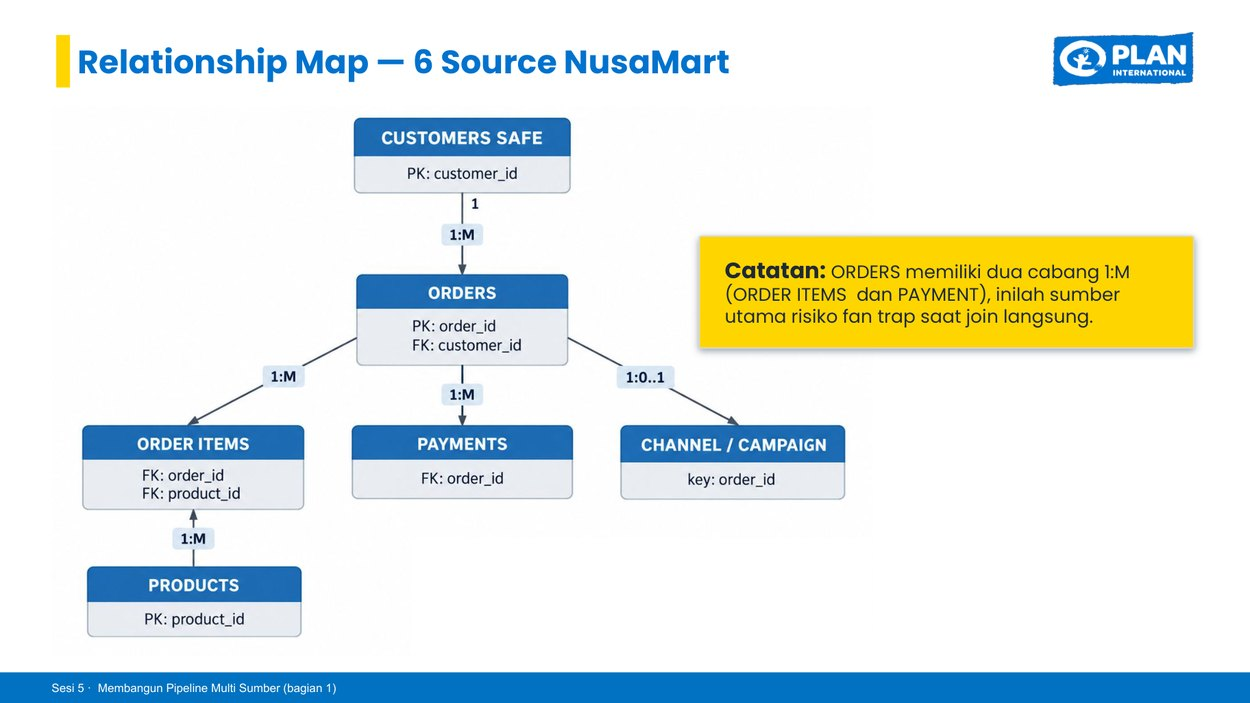

*Diagram hubungan data. Perhatikan Order Items dan Payments sama-sama bisa berulang pada satu order. — visual bersumber dari **PPT S5 halaman 16**, bukan screenshot hasil RUN Notebook.*

---
# PRAKTIK 2 — Manajer meminta dataset satu baris per pesanan

**CASE:** NusaMart tidak ingin 760 item dan 337 pembayaran diartikan sebagai 1.097 order. Dataset akhir harus **1 row = 1 order**.

**TUJUAN:** memahami grain, key, cardinality, menentukan Join Plan sebelum coding, dan mencatat baseline angka sumber.

**PAHAMI:** `order_id` adalah identitas order; wajar jika berulang pada Order Items dan Payments. `groupby` seperti mengumpulkan semua nota untuk order yang sama menjadi satu rekap. Jangan menghapus baris pembayaran/item hanya karena `order_id` berulang.

**LIHAT CONTOH:** tiga item dan dua pembayaran dari satu order harus tetap menjadi **satu baris final**, dengan ringkasan 3 item dan total pembayaran, bukan enam baris gabungan.

**JUDGMENT awal:** Orders menjadi base; Order Items dan Payments harus diringkas per order sebelum final join. Products memperkaya item sebelum agregasi; Customers Safe dan Channel/Campaign tidak boleh menyebabkan hilangnya Orders.

## Section 3 — Grain, Key & Cardinality / Praktik 2

**Analogi:** Dalam satu nota belanja ada banyak barang dan pembayaran bisa dicicil. `order_id` unik pada tabel Orders, tetapi **boleh muncul berulang** di tabel Order Items dan Payments. Pengulangan tersebut **belum tentu data duplikat yang salah**.

**Istilah:**
- **Grain:** satu baris membahas apa (`order`, `item`, `payment`, `customer`).
- **Primary/candidate key:** identitas unik sebuah baris pada grain tersebut.
- **Foreign/join key:** penghubung antarsumber; tidak wajib unik di kedua sisi.
- **Cardinality:** satu-ke-satu, satu-ke-banyak, dan seterusnya.

**Tugas:** Jalankan pengecekan. Setelah hasil muncul, lengkapi `02_Join_Plan` JP-01 sampai JP-05. **Jangan menulis corrected join dulu.**

**Sebelum selesai Praktik 1:** gunakan `key_results` yang akan tampil untuk melengkapi key di `01_Source_Inventory`. Setelah enam baris terisi dan dicek, baru pilih `REVIEWED` pada J7–J12.


In [5]:
def key_check(df, key):
    return {
        "rows": len(df),
        "unique_key": int(df[key].nunique(dropna=False)),
        "duplicate_extra": int(df.duplicated(key, keep="first").sum()),
        "missing_key": int(df[key].isna().sum()),
        "is_unique": bool(df[key].is_unique),
    }

keys = {
    "Orders": (orders, "order_id"),
    "Order Items": (order_items, "order_item_id"),
    "Customers Safe": (customers, "customer_id"),
    "Payments": (payments, "payment_id"),
    "Products": (products, "product_id"),
    "Channel/Campaign": (channel_campaign, "order_id"),
}
key_results = pd.DataFrame([{"source": n, "key": k, **key_check(df, k)} for n, (df, k) in keys.items()])
display(key_results)

print("\nJumlah item per order (contoh distribusi):")
display(order_items.groupby("order_id").size().describe().to_frame("items_per_order"))
print("\nJumlah payment per order (contoh distribusi):")
display(payments.groupby("order_id").size().describe().to_frame("payments_per_order"))

print("GRAIN/KEY CHECK: REVIEW REQUIRED — pastikan hubungan 1:M dipahami sebelum join.")

,source,key,rows,unique_key,duplicate_extra,missing_key,is_unique
0,Orders,order_id,320,320,0,0,True
1,Order Items,order_item_id,760,760,0,0,True
2,Customers Safe,customer_id,215,215,0,0,True
3,Payments,payment_id,337,337,0,0,True
4,Products,product_id,45,45,0,0,True
5,Channel/Campaign,order_id,300,300,0,0,True



Jumlah item per order (contoh distribusi):


,items_per_order
count,320.000000
mean,2.375000
std,0.484881
min,2.000000
25%,2.000000
50%,2.000000
75%,3.000000
max,3.000000



Jumlah payment per order (contoh distribusi):


,payments_per_order
count,320.000000
mean,1.053125
std,0.224634
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,2.000000


GRAIN/KEY CHECK: REVIEW REQUIRED — pastikan hubungan 1:M dipahami sebelum join.


### ⏸ STOP 1C + 2A — Selesaikan Source Inventory, mulai Join Plan

**BACA:** `key_results` pada Section 3. `is_unique=True` berarti nilai key tidak berulang, sedangkan `duplicate_extra` menghitung baris tambahan dengan key sama. Periksa juga distribusi `items_per_order` dan `payments_per_order`.

**LENGKAPI Sheet `01_Source_Inventory`:** **E** = Candidate/Primary Key dari kolom `key`, **F** = Join Key sesuai relationship, kemudian **J7:J12 = REVIEWED** hanya setelah D–I sesuai dan struktur sudah ditinjau.

**Worked example baris 7:** A=`Orders`, B=`nusamart_orders_s5.csv`, C=`CSV`, D=`1 row = 1 order`, E=`order_id`, F=`order_id; customer_id`, G=`Base; 1 order per row`, H=`Raw S5 read-only`, I=`Starter Section 1–3`, J=`REVIEWED` **setelah review**.

**CHECKPOINT Praktik 1:** 6/6 source dikenali; key dicek; tahu `Orders.order_id` tidak berulang, tetapi `order_items.order_id` dan `payments.order_id` boleh berulang. **Pindah Praktik 2 tanpa menjalankan join dulu.**

**MULAI Sheet `02_Join_Plan` baris 7–11** setelah memahami hubungan tersebut. JP-01=Order Items→Products, JP-02=Orders→Customers Safe, JP-03=Orders→Item Aggregate, JP-04=Orders→Payments Aggregate, JP-05=Orders→Channel/Campaign.

### LIHAT CONTOH — JP-04: Orders → Payments Aggregate (Sheet 02 baris 10)

| Sel | Contoh pengisian setelah pemeriksaan | Alasan |
|---|---|---|
| E10 | `1 row/order` | Orders adalah base |
| F10 | `Raw 1 row/payment; aggregate 1 row/order` | Pembayaran bisa berulang |
| G10 | `1 row = 1 order` | Grain target akhir |
| H10 | `Raw 1:M → after agg 1:1` | Relationship berubah setelah agregasi |
| I10 | `Payments berulang dapat menggandakan order_total` | Risiko fan trap |
| J10 | `AGGREGATE BEFORE JOIN` | Pilihan dropdown. Implementasi agregasinya adalah `SUM(amount_paid) per order_id`. |
| K10 | `LEFT JOIN — KEEP ALL ORDERS` | Pilihan dropdown. Orders tetap utuh; unmatched tetap diperiksa. |
| L10 | `REVIEWED` **setelah mentor memeriksa** | Tidak boleh dipilih hanya agar tampak READY |

**CARA ISI JP-01–JP-05:** A–D sudah disiapkan sebagai identitas relationship. Isi **E–K** dari grain/key, lalu gunakan **L7–L11** hanya setelah review. Pastikan target grain JP-01 `1 row = 1 item` dan JP-02–05 `1 row = 1 order` sesuai formula pada Working Paper.

**PROMPT Antigravity untuk review RENCANA (belum coding):**
```text
Tinjau Join Plan NusaMart JP-01 sampai JP-05 dengan target hasil satu baris
per order_id. Jelaskan grain, join key, cardinality, risiko double-counting,
kebutuhan agregasi, dan perlakuan unmatched. Jangan menulis corrected join
sebelum saya menyetujui rencananya. Jangan gunakan PII mentah.
```

In [6]:
# Ubah hanya setelah JOIN PLAN JP-01 sampai JP-05 selesai direview.
JOIN_PLAN_REVIEWED = True  # GANTI False menjadi True setelah disetujui/review

if JOIN_PLAN_REVIEWED:
    print("JOIN PLAN: REVIEWED — boleh lanjut menyusun corrected join di Section 7.")
else:
    print("JOIN PLAN: PENDING — lengkapi 02_Join_Plan sebelum corrected join.")

JOIN PLAN: REVIEWED — boleh lanjut menyusun corrected join di Section 7.


### ⏸ STOP 2B — Review Join Plan sebelum memberi instruksi coding

**BUKA:** `02_Join_Plan`, baris 7–11, periksa E–K dan status L. **Jangan mengubah `JOIN_PLAN_REVIEWED = True` hanya untuk meniadakan HOLD.**

**Judgment wajib:**
- JP-01 Products tidak boleh menggandakan baris item.
- JP-03 Order Items perlu diringkas ke grain order.
- JP-04 Payments perlu diringkas ke grain order.
- JP-05 LEFT JOIN dan mencatat 20 order tanpa mapping, bukan menghapus order tersebut.

**Contoh pertanyaan mentor:** Mengapa `order_id` berulang pada Payments belum tentu data duplikat? Mengapa hasil akhir harus satu baris per order?

**CHECKPOINT:** lima relationship direview. Jika belum, tetap `JOIN_PLAN_REVIEWED=False` dan **STOP**. Setelah disetujui, ubah flag pada cell di atas menjadi `True`, lalu lanjut ke Section 4.

## Section 4 — Baseline Metrics (angka sebelum join) / Praktik 2

**Analogi:** Catat jumlah uang di laci kasir **sebelum** memindahkan barang. Setelah proses join, jumlah transaksi tidak seharusnya mendadak berubah hanya karena tabel diperkaya.

**Tugas:** Jalankan kode berikut. Masukkan baseline pada `03_Validation_Evidence` bagian **VE-01 sampai VE-03**.

**Contoh referensi:** 320 unique orders; total order **Rp42.061.000**; total payment **Rp42.061.000**. Ini angka dari paket referensi S5, bukan angka yang boleh ditebak.

**Pengisian VE-01–03:** kolom D berisi angka pembanding dari source, kolom E adalah angka yang benar-benar muncul dari output baseline. Pada baseline ini D dan E biasanya sama, karena belum terjadi join. Status G baru PASS jika sudah dibuktikan.


In [7]:
baseline = {
    "orders_rows": len(orders),
    "unique_orders": int(orders["order_id"].nunique()),
    "order_total": float(orders["order_total"].sum()),
    "payment_total": float(payments["amount_paid"].sum()),
}
display(pd.DataFrame([baseline], index=["BASELINE"]));
print("BASELINE CHECK: RECORDED — jangan mengubah source jika ada selisih.")

,orders_rows,unique_orders,order_total,payment_total
BASELINE,320,320,42061000.0,42061000.0


BASELINE CHECK: RECORDED — jangan mengubah source jika ada selisih.


### ⏸ STOP 2C — Salin baseline, bukan menebak angka

**BACA:** tabel `BASELINE` di Section 4: `unique_orders`, `order_total`, `payment_total`.

**ISI `03_Validation_Evidence`:**

| Baris | Check | D = Expected | E = Actual Section 4 | G = status |
|---|---|---:|---:|---|
| **7 · VE-01** | Unique order count | 320 | ambil `unique_orders` | PASS bila cocok |
| **8 · VE-02** | SUM(order_total) | 42.061.000 | ambil `order_total` | PASS bila cocok |
| **9 · VE-03** | SUM(amount_paid) | 42.061.000 | ambil `payment_total` | PASS bila cocok |

**F adalah formula selisih otomatis**, jangan diketik. **H7:H9** = `Starter Section 4`; **I** = alasan pembanding cocok/tidak; **J** = cek source jika tidak cocok.

**INTERPRETASI:** baseline ialah nilai sumber SEBELUM join. Jika nanti penjualan hasil join tiba-tiba menjadi lebih besar, belum tentu bisnis bertumbuh; bisa jadi ada baris yang dihitung berulang.

**CHECKPOINT Praktik 2:** tiga selisih bernilai nol dan Join Plan direview. **LANJUT ke eksperimen salah yang disengaja pada Praktik 3.**

---
# PRAKTIK 3 — Mengapa nilai transaksi tampak melonjak setelah join?

**CASE:** Kode tim NusaMart berjalan tanpa error, tetapi jumlah baris meningkat dan total penjualan menyimpang. Manajer meminta bukti apakah ini pertumbuhan bisnis sungguhan atau kesalahan integrasi.

**TUJUAN:** menjalankan naive join **sebagai percobaan salah**, menemukan fan trap, membuktikan perkalian baris pada satu order, dan **menolak** output yang menyesatkan.

**PAHAMI:** jika 1 order mempunyai 3 item dan 2 payment, naive join dapat membuat **3 × 2 = 6** kombinasi. Ini bukan 6 order baru dan bukan bukti penjualan naik.

**JUDGMENT yang dinilai:** `NAIVE JOIN VALIDATION: EXPECTED FAIL` = peserta berhasil menemukan masalah; **jangan gunakan naive join untuk dashboard**.

## Section 5 — Naive Join: Sengaja Menunjukkan Hasil yang Salah / Praktik 3

**Ini bukan contoh join yang boleh dipakai untuk laporan!** Kita sengaja menggabungkan dua tabel child 1:M tanpa agregasi supaya terlihat risiko *fan trap*.

**Tugas:** Jalankan cell, bandingkan `BASELINE` dan `NAIVE_JOIN`, lalu isi `03_Validation_Evidence` bagian **VE-04 sampai VE-06**.

**Jika jumlah baris membesar:** itu merupakan **FAIL yang diharapkan** pada latihan ini. Notebook tidak error, tetapi metrik analitiknya menjadi tidak benar.

**Pengisian VE-04–06:** D = nilai baseline Section 4, E = angka NAIVE_JOIN Section 5. Kolom F menghitung selisih otomatis. Pada paket latihan ini, G = **FAIL yang memang diharapkan**, bukan kegagalan peserta.


In [8]:
naive = (
    orders
    .merge(order_items, on="order_id", how="left")
    .merge(payments, on="order_id", how="left", suffixes=("", "_payment"))
)
naive_metrics = {
    "orders_rows": len(naive),
    "unique_orders": int(naive["order_id"].nunique()),
    "order_total": float(naive["order_total"].sum()),
    "payment_total": float(naive["amount_paid"].sum()),
}
display(pd.DataFrame([baseline, naive_metrics], index=["BASELINE", "NAIVE_JOIN"]))
naive_looks_correct = (
    naive_metrics["orders_rows"] == baseline["orders_rows"]
    and abs(naive_metrics["order_total"] - baseline["order_total"]) < 0.01
    and abs(naive_metrics["payment_total"] - baseline["payment_total"]) < 0.01
)
print("NAIVE JOIN VALIDATION:", "REVIEW (tidak terjadi inflation)" if naive_looks_correct else "EXPECTED FAIL — angka berlipat, perlu diperbaiki")

,orders_rows,unique_orders,order_total,payment_total
BASELINE,320,320,42061000.0,42061000.0
NAIVE_JOIN,802,320,109177000.0,103431000.0


NAIVE JOIN VALIDATION: EXPECTED FAIL — angka berlipat, perlu diperbaiki


### ⏸ STOP 3A — Isi bukti kesalahan naive join (Sheet 03)

**BACA:** `BASELINE` vs `NAIVE_JOIN` pada Section 5. Referensi paket S5: 320→802 baris; Rp42.061.000→Rp109.177.000 untuk `order_total`; Rp42.061.000→Rp103.431.000 untuk `amount_paid`.

**ISI `03_Validation_Evidence`**:

| Baris | D = baseline | E = naive join | F = selisih otomatis | G |
|---|---:|---:|---:|---|
| 10 · VE-04 | 320 | 802 | 482 | **FAIL** |
| 11 · VE-05 | 42.061.000 | 109.177.000 | 67.116.000 | **FAIL** |
| 12 · VE-06 | 42.061.000 | 103.431.000 | 61.370.000 | **FAIL** |

**H**=`Starter Section 5`, **I**=fan trap/row multiplication, **J**=`Investigasi Section 6, lalu lakukan agregasi sebelum join`.

**PENTING:** Dropdown G10:G12 harus **`FAIL`** (bukan teks baru `FAIL (EXPECTED)`); tulis kata *disengaja* pada kolom alasan. Ini menjaga formula Working Paper tetap bekerja.

**JUDGMENT:** Tolak naive join sebagai dasar laporan. **LANJUT ke Section 6 untuk menelusuri satu order.**

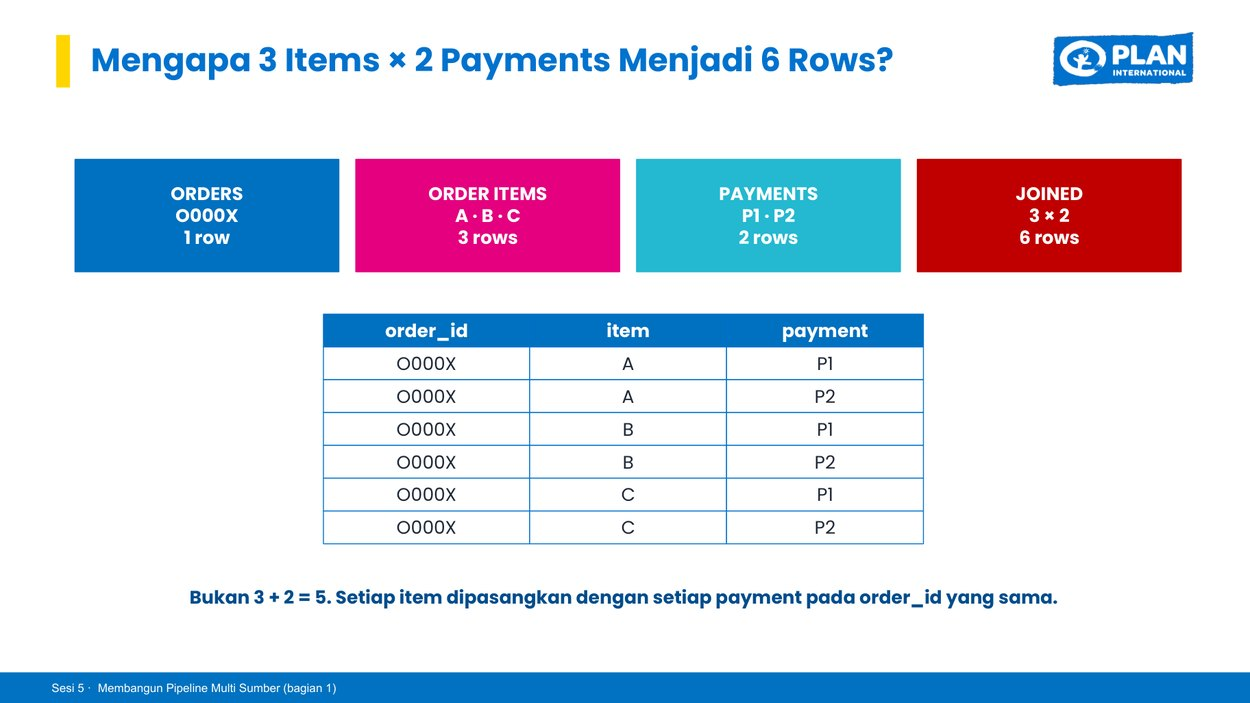

*Contoh fan trap: satu order dengan 3 items dan 2 payments berubah menjadi 6 baris dalam naive join. — visual bersumber dari **PPT S5 halaman 21**, bukan screenshot hasil RUN Notebook.*

## Section 6 — Investigasi Fan Trap / Praktik 3

**Tugas:** Cari satu `order_id` yang punya lebih dari satu item **dan** lebih dari satu pembayaran. Gunakan data sebagai bukti mengapa naive join menggandakan angka.

**Contoh referensi paket S5:** `O0015` mempunyai **3 item × 2 payment = 6 kombinasi**. Jangan anggap keenam baris sebagai enam transaksi baru.

**Jika tabel kandidat kosong:** jangan menjalankan `.index[0]` tanpa cek; minta fasilitator memastikan source sudah sama.

**Setelah hasil fan trap muncul:** di Sheet `03_Validation_Evidence` isi **baris 21**, kolom A–I. Bandingkan hasil `item_rows × payment_rows` dengan jumlah baris nyata pada naive join untuk order yang dipilih.


In [10]:
fan = (
    order_items.groupby("order_id").size().rename("item_rows").to_frame()
    .join(payments.groupby("order_id").size().rename("payment_rows"))
    .fillna(0)
)
fan["expected_cross_rows"] = fan["item_rows"] * fan["payment_rows"]
fan = fan.sort_values(["expected_cross_rows", "item_rows"], ascending=False)
display(fan.head(10))

candidates = fan.loc[(fan["item_rows"] > 1) & (fan["payment_rows"] > 1)]
if candidates.empty:
    print("FAN TRAP EVIDENCE: NOT FOUND — cek package dan kolom join; tanyakan trainer.")
else:
    candidate_order_id = "O0015" if "O0015" in candidates.index else candidates.index[0]
    print("Contoh order yang diperiksa:", candidate_order_id)
    print("Items × Payments:", int(fan.loc[candidate_order_id, "item_rows"]),
          "×", int(fan.loc[candidate_order_id, "payment_rows"]),
          "=", int(fan.loc[candidate_order_id, "expected_cross_rows"]))
    fan_actual_rows = int(naive["order_id"].eq(candidate_order_id).sum())
    display(naive.loc[naive["order_id"] == candidate_order_id,
                      ["order_id", "order_item_id", "payment_id", "line_total", "amount_paid"]])
    print("Actual rows pada naive join:", fan_actual_rows)
    print("Baris 21 WP: A=order_id, B=item_rows, C=payment_rows, D=hasil kali, E=actual rows, F=Section 6.")
    print("FAN TRAP: EVIDENCE FOUND — catat order_id, row multiplication dan alasan pada WP 03.")

,item_rows,payment_rows,expected_cross_rows
order_id,,,
O0015,3,2,6
O0057,3,2,6
O0069,3,2,6
O0083,3,2,6
O0142,3,2,6
O0169,3,2,6
O0226,3,2,6
O0304,3,2,6
O0077,2,2,4


Contoh order yang diperiksa: O0015
Items × Payments: 3 × 2 = 6


,order_id,order_item_id,payment_id,line_total,amount_paid
34,O0015,OI00035,PAY00015,90000,121200
35,O0015,OI00035,PAY00016,90000,80800
36,O0015,OI00036,PAY00015,90000,121200
37,O0015,OI00036,PAY00016,90000,80800
38,O0015,OI00037,PAY00015,22000,121200
39,O0015,OI00037,PAY00016,22000,80800


Actual rows pada naive join: 6
Baris 21 WP: A=order_id, B=item_rows, C=payment_rows, D=hasil kali, E=actual rows, F=Section 6.
FAN TRAP: EVIDENCE FOUND — catat order_id, row multiplication dan alasan pada WP 03.


### ⏸ STOP 3B — Buktikan fan trap pada satu order (Sheet 03, baris 21)

**BACA:** dari Section 6 ambil `candidate_order_id`, `item_rows`, `payment_rows`, `expected_cross_rows`, dan `Actual rows pada naive join`.

**Contoh referensi `O0015`:** 3 item × 2 pembayaran = **6 baris**. Gunakan order ini bila benar-benar muncul pada output peserta.

**ISI `03_Validation_Evidence`, Fan Trap Evidence baris 21:**

| Sel | Contoh | Sumber |
|---|---|---|
| A21 | `O0015` | `candidate_order_id` Section 6 |
| B21 | 3 | `item_rows` |
| C21 | 2 | `payment_rows` |
| D21 | 6 | `expected_cross_rows` |
| E21 | 6 | `Actual rows pada naive join` |
| F21 | `Starter Section 6` | Evidence location |
| G21 | `3 item × 2 payment = 6 baris` | Penjelasan |
| H21 | **PASS** | Bukti perkalian sesuai, BUKAN naive join benar |
| I21 | `Investigasi selesai` | Reviewer note |

**CHECKPOINT:** jelaskan mengapa `H21=PASS` tetapi `G10:G12=FAIL`. Jika kamu dapat menjawab, **LANJUT Praktik 4 untuk memperbaiki join**.

G10 bertambah baris dan terjadi perhitungan berulang pada G11 dan G12

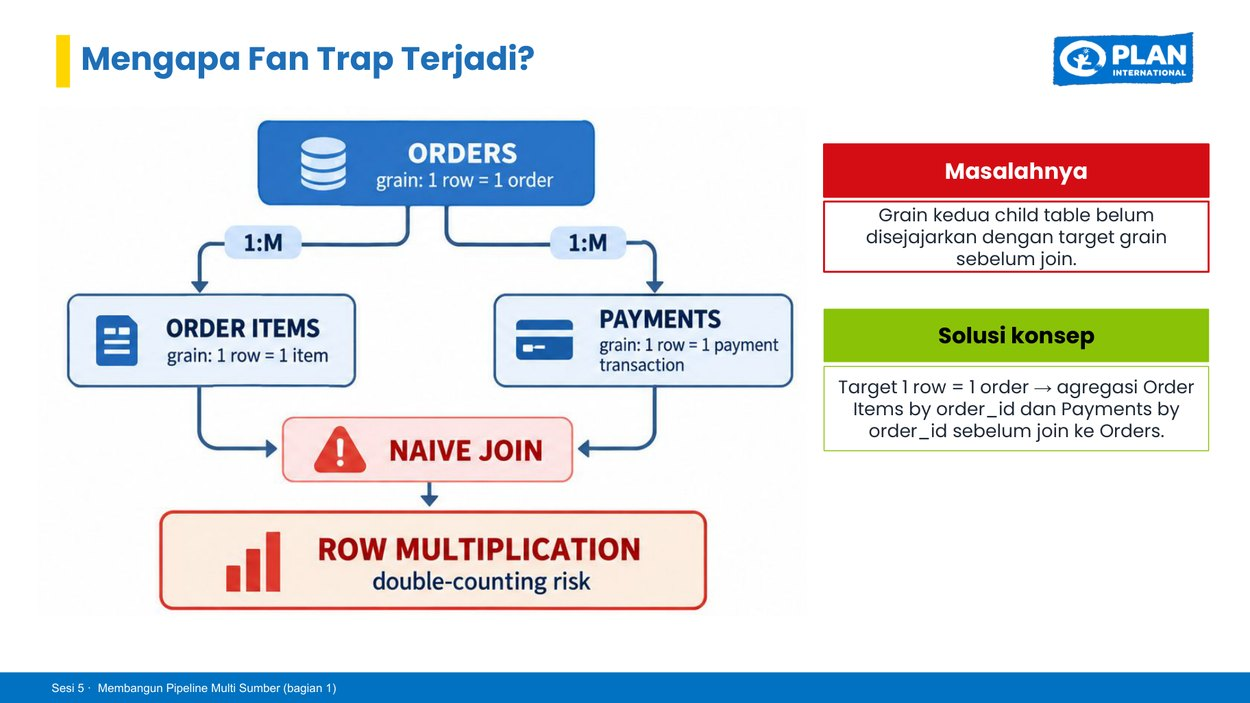

*Solusi konsep: ringkas setiap child ke grain order sebelum join ke Orders. — visual bersumber dari **PPT S5 halaman 23**, bukan screenshot hasil RUN Notebook.*

---
# PRAKTIK 4 — Perbaiki join agar laporan NusaMart dapat dipercaya

**CASE:** Manajer meminta kamu memperbaiki laporan dan mempertahankan **seluruh 320 order**. Beberapa order boleh tidak mempunyai campaign mapping, tetapi ordernya **tidak boleh hilang**.

**TUJUAN:** memberikan task brief yang benar ke Antigravity, meninjau rencana/kode, mengimplementasikan 7A–7D, dan membuktikan hasil dengan validasi independen.

**PAHAMI:** ringkas child table **sebelum** final join (nota barang dan pembayaran diringkas per pesanan); barulah gabungkan ke Orders. `LEFT JOIN` menjaga pesanan base tidak hilang ketika sumber pasangan tidak lengkap.

**LIHAT CONTOH sasaran referensi:** 320 baris × 19 kolom; 320 `order_id` unik; 0 duplikat; total order dan payment Rp42.061.000; 20 order tanpa Channel/Campaign mapping **dijelaskan, bukan dihapus**.

**JUDGMENT:** Kode Agent yang terlihat rapi belum cukup. Hasil harus sama dengan baseline, relationship cocok, dan pengecekan SQL independen PASS.

## Section 7 — Corrected Pipeline | Praktik 4

### Alur wajib: Judgment → Instruksi Agent → Review Plan → Implement → Baca Output

**Aturan utama:** 7A–7D merupakan tempat praktik menulis kode bersama Antigravity. **Bukan** soal menghafal sintaks Python dan **bukan** meng-copy kode tanpa memahami keputusannya.

**Langkah di Antigravity:**
1. Buka workspace proyek yang berisi Notebook ini dan folder `practice/sesi_05/source/`.
2. Pastikan Sheet 02 Join Plan sudah direview, dan cell `JOIN_PLAN_REVIEWED = True` hanya diubah setelah disetujui mentor.
3. Kirim task brief global berikut. **Minta PLAN DULU, jangan langsung menulis kode.**
4. Cocokkan jawaban Agent dengan JP-01–JP-05; tolak usulan yang langsung menggabungkan raw Order Items dan raw Payments ke Orders.
5. Kerjakan 7A, jalankan checkpoint; baru 7B; 7C; terakhir 7D. Tempel kode Agent **pada area TODO yang ditentukan**, jangan menghapus pemeriksaan/checkpoint di bawahnya.

**TASK BRIEF GLOBAL (salin ke Agent):**
```text
Saya adalah peserta Bootcamp Data Analyst yang belum mahir Python/SQL.
Bantu mengimplementasikan Section 7A–7D Starter Notebook S5 NusaMart.
Target akhir adalah satu baris per order_id. Gunakan 6 DataFrame yang
sudah dibaca di Section 1 dan Join Plan JP-01 sampai JP-05 yang sudah
direview. JANGAN mengubah raw source, JANGAN membuka PII mentah,
JANGAN melakukan join Order Items mentah dan Payments mentah ke Orders.
Usulkan rencana grain, key, agregasi, LEFT JOIN, serta validasi terlebih
dahulu. Tunggu persetujuan saya sebelum menulis kode untuk tiap TODO.
Jelaskan kode dengan komentar sederhana. Jangan mengubah kode helper
validasi Section 8 dan Section 9 untuk sekadar menghasilkan PASS.
```

**Cek rencana Agent:** (a) Products→Items tidak menggandakan item; (b) Items diringkas per order; (c) Payments diringkas per order; (d) Orders tetap base; (e) mismatch harus ditandai HOLD, bukan ditutupi.

### Peta kerja 7A–7D — Satu tugas kecil, satu checkpoint

| Bagian | Instruksi | Nama DataFrame yang HARUS dibuat | Bukti lulus |
|---|---|---|---|
| **7A** | Enrich Order Items dengan Products via `product_id` | `items_enriched` | Tetap **760** baris pada dataset referensi, tidak ada item hilang/tergandakan |
| **7B** | Aggregate item per `order_id` | `items_order` | Unik per order, `item_amount_total` sama total sumber item |
| **7C** | Aggregate pembayaran per `order_id` | `payments_order` | Unik per order, `amount_paid_total` sama total pembayaran sumber |
| **7D** | Final LEFT JOIN ke Orders dengan Customers Safe dan Channel/Campaign | `final_integrated` | Target **1 row = 1 order**, lanjut cek Section 8–9 |

**PENTING:** Nama kolom metrik 7B wajib `item_count`, `quantity_total`, `item_amount_total`, `unique_product_count`, `unique_category_count`. Nama metrik 7C wajib `payment_count`, `amount_paid_total`. Mengubah nama ini menyebabkan validasi Section 8–9 tidak mengenali hasil.

### LIHAT CONTOH cara mereview kode Agent

Jika Agent menawarkan `orders.merge(order_items).merge(payments)` tanpa agregasi, **tolak**, meskipun kodenya mungkin berjalan. Minta ringkasan item dan pembayaran per `order_id` terlebih dahulu.

**Cara membaca checkpoint code di bawah:** `PENDING` artinya kamu masih harus mengerjakan TODO; `HOLD` artinya hasil belum sesuai; `PASS` menandakan hanya checkpoint tahap tersebut lulus, **bukan** otomatis seluruh pipeline PASS.

### 7A — Perkaya Order Items dengan Products

**Tujuan:** Pada baris item, cari informasi produk berdasarkan `product_id`, tanpa mengubah jumlah item.

**Contoh Task Brief untuk Antigravity (boleh disesuaikan):**

```text
Gunakan DataFrame order_items dan products yang sudah ada di Notebook S5.
Saya ingin menambah atribut produk ke baris order_items lewat product_id.
Target grain TIDAK boleh berubah: 1 row = 1 order item.
Tunjukkan rencana dan kolom hasil terlebih dahulu. Jangan mengubah source.
Setelah saya review, tulis kode untuk mengisi items_enriched saja.
Berikan cek jumlah baris sebelum-sesudah dan missing product_id.
```

**Review plan Agent:** Apakah `products.product_id` unik? Apakah `LEFT JOIN` sesuai kebutuhan? Apakah jumlah item tetap 760 untuk paket referensi?

**Working Paper:** `02_Join_Plan → JP-01`.

In [12]:
# TODO 7A — Perkaya order_items dengan atribut dari products lewat product_id (LEFT JOIN)
items_enriched = order_items.merge(
    products,
    on="product_id",
    how="left"
)

# Cek pra-validasi independen
print("--- Pengecekan 7A (Sebelum & Sesudah) ---")
print("Jumlah baris sebelum join (order_items) :", len(order_items))
print("Jumlah baris sesudah join (items_enriched):", len(items_enriched))
print("Jumlah item dengan kategori hilang (missing):", items_enriched["category"].isna().sum())
print("Apakah ID item tetap unik?                :", items_enriched["order_item_id"].is_unique)
print("-----------------------------------------")


--- Pengecekan 7A (Sebelum & Sesudah) ---
Jumlah baris sebelum join (order_items) : 760
Jumlah baris sesudah join (items_enriched): 760
Jumlah item dengan kategori hilang (missing): 0
Apakah ID item tetap unik?                : True
-----------------------------------------


In [11]:
# TODO 7A — isi BAWAH baris ini dengan kode hasil review bersama Antigravity.
# Buat pandas DataFrame `items_enriched` dari order_items + Products via product_id.
# Contoh kerja: items_enriched = order_items.merge(...)
# JANGAN hapus pemeriksaan di bawah. Ubah None hanya setelah kode Agent siap.
items_enriched = order_items.merge(
    products,
    on="product_id",
    how="left"
)

# Jika bagian pipeline diubah, validasi PASS lama di memori tidak berlaku.
pipeline_pass = False

stage_7a_pass = False
if items_enriched is None:
    print("7A PENDING — minta kode Agent, review, lalu ganti TODO/None di atas.")
elif not isinstance(items_enriched, pd.DataFrame):
    print("7A HOLD — items_enriched harus pandas DataFrame, bukan tipe lain.")
else:
    needed = {"order_id", "order_item_id", "product_id", "quantity", "line_total", "category"}
    absent = needed - set(items_enriched.columns)
    row_ok = len(items_enriched) == len(order_items)
    id_ok = "order_item_id" in items_enriched and items_enriched["order_item_id"].is_unique
    stage_7a_pass = bool(not absent and row_ok and id_ok)
    display(items_enriched.head(3))
    print("7A rows:", len(items_enriched), "| source items:", len(order_items))
    if absent: print("7A kolom belum ada:", sorted(absent))
    print("7A CHECK:", "PASS" if stage_7a_pass else "HOLD — periksa product_id, jumlah baris, dan kolom")

,order_item_id,order_id,product_id,quantity,unit_price,line_total,product_name,category,brand,standard_price,active_status
0,OI00001,O0001,P005,2,35000,70000,Product 05,Groceries,NusaDaily,35000,Active
1,OI00002,O0001,P012,3,25000,75000,Product 12,Snacks,NusaFresh,25000,Active
2,OI00003,O0001,P002,2,30000,60000,Product 02,Snacks,NusaFresh,30000,Active


7A rows: 760 | source items: 760
7A CHECK: PASS


### ⏸ STOP 4A.1 — Review output 7A

**BACA:** `7A rows`, tiga baris contoh, serta `7A CHECK`. **HARAPAN:** `items_enriched` tetap berisi 760 item pada paket S5, `order_item_id` tetap unik, atribut `category` berasal dari Products.

**INTERPRETASI:** menambah informasi produk **tidak boleh mengubah jumlah baris item**. Jika 760 berubah, kemungkinan join Products menggandakan atau kehilangan item. **JUDGMENT:** jika bukan PASS, jangan jalankan 7B.

### 7B — Ringkas Item menjadi Satu Baris per Order

**Mengapa?** Item level punya banyak baris per order. Kita butuh ringkasannya sebelum digabungkan ke Orders.

**Task Brief lanjutan untuk Agent:**

```text
Lanjutkan dari items_enriched yang sudah saya review.
Kelompokkan berdasarkan order_id, hasilkan satu baris per order.
Saya membutuhkan kolom minimal: order_id, item_count,
quantity_total, item_amount_total (SUM line_total),
unique_product_count (NUNIQUE product_id), dan
unique_category_count (NUNIQUE category dari tabel Products).
Jelaskan cara menghitungnya dan cek order_id tidak duplikat.
Penting: kategori hasil enrichment harus ikut terbawa ke agregasi,
agar penggunaan sumber Products dapat ditelusuri pada hasil akhir.
Jangan langsung join ke Orders; cukup buat items_order.
```

**Checkpoint:** `items_order["order_id"].is_unique == True`; total nilai item sebelum dan sesudah ringkas konsisten. `unique_category_count` membuktikan atribut Products ikut menjadi bagian hasil integrasi.

**Working Paper:** `02_Join_Plan → JP-03`.

In [14]:
# TODO 7B — Ringkas items_enriched menjadi satu baris per order_id
items_order = items_enriched.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "count"),
    quantity_total=("quantity", "sum"),
    item_amount_total=("line_total", "sum"),
    unique_product_count=("product_id", "nunique"),
    unique_category_count=("category", "nunique"),
)

# Cek pra-validasi independen
print("--- Pengecekan 7B (Hasil Agregasi) ---")
print("Jumlah baris items_order            :", len(items_order))
print("Apakah order_id 100% unik?          :", items_order["order_id"].is_unique)
print("Total nilai item sebelum diringkas  :", float(order_items["line_total"].sum()))
print("Total nilai item sesudah diringkas  :", float(items_order["item_amount_total"].sum()))
print("Selisih nilai item                  :", abs(float(items_order["item_amount_total"].sum()) - float(order_items["line_total"].sum())))
print("-------------------------------------")


--- Pengecekan 7B (Hasil Agregasi) ---
Jumlah baris items_order            : 320
Apakah order_id 100% unik?          : True
Total nilai item sebelum diringkas  : 42061000.0
Total nilai item sesudah diringkas  : 42061000.0
Selisih nilai item                  : 0.0
-------------------------------------


In [13]:
# TODO 7B — gunakan items_enriched hasil 7A; buat 1 row per order_id.
# Metrik: item_count, quantity_total, item_amount_total,
# unique_product_count, unique_category_count.
items_order = items_enriched.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "count"),
    quantity_total=("quantity", "sum"),
    item_amount_total=("line_total", "sum"),
    unique_product_count=("product_id", "nunique"),
    unique_category_count=("category", "nunique"),
)
pipeline_pass = False

stage_7b_pass = False
if not globals().get("stage_7a_pass", False):
    print("7B HOLD — selesaikan/review 7A lebih dahulu.")
elif items_order is None:
    print("7B PENDING — isi agregasi items_order sesuai Join Plan bersama Agent.")
elif not isinstance(items_order, pd.DataFrame):
    print("7B HOLD — items_order harus DataFrame.")
else:
    needed = {"order_id", "item_count", "quantity_total", "item_amount_total",
              "unique_product_count", "unique_category_count"}
    absent = needed - set(items_order.columns)
    unique_ok = "order_id" in items_order and items_order["order_id"].is_unique
    total_ok = ("item_amount_total" in items_order and
                pd.api.types.is_numeric_dtype(items_order["item_amount_total"]) and
                abs(float(items_order["item_amount_total"].sum()) - float(order_items["line_total"].sum())) < .01)
    cats_ok = "unique_category_count" in items_order and items_order["unique_category_count"].notna().all()
    stage_7b_pass = bool(not absent and unique_ok and total_ok and cats_ok)
    display(items_order.head(3))
    if absent: print("7B kolom belum ada:", sorted(absent))
    print("7B CHECK:", "PASS" if stage_7b_pass else "HOLD — periksa grain, sum line_total, kategori")

,order_id,item_count,quantity_total,item_amount_total,unique_product_count,unique_category_count
0,O0001,3,7,205000,3,2
1,O0002,2,2,40000,2,1
2,O0003,3,4,88000,3,3


7B CHECK: PASS


### ⏸ STOP 4A.2 — Review output 7B

**BACA:** contoh `items_order`, `7B CHECK`, dan apakah `order_id` unik. `item_amount_total` harus cocok dengan SUM `order_items.line_total` dari sumber.

**INTERPRETASI:** setiap order kini hanya punya satu ringkasan barang. **JUDGMENT:** jangan lanjut 7D jika `item_amount_total` tidak reconcile, meskipun nama kolom ada.

### 7C — Ringkas Payments menjadi Satu Baris per Order

**Task Brief lanjutan untuk Agent:**

```text
Gunakan DataFrame payments. Kelompokkan transaksi pembayaran per order_id.
Hasilkan satu baris per order dengan kolom minimal:
order_id, payment_count, amount_paid_total (SUM amount_paid).
Jangan menghapus payment ganda yang sah.
Cek bahwa SUM amount_paid_total = SUM amount_paid dari source.
Simpan DataFrame dengan nama payments_order.
```

**Checkpoint:** payment yang berulang per order merupakan transaksi berbeda, tidak otomatis duplicate.

**Working Paper:** `02_Join_Plan → JP-04`.

In [16]:
# TODO 7C — Ringkas pembayaran per order_id (menjumlahkan split payment, bukan membuangnya)
payments_order = payments.groupby("order_id", as_index=False).agg(
    payment_count=("payment_id", "count"),
    amount_paid_total=("amount_paid", "sum"),
)

# Cek pra-validasi independen
print("--- Pengecekan 7C (Hasil Agregasi Pembayaran) ---")
print("Jumlah transaksi sumber (payments)        :", len(payments))
print("Jumlah pesanan setelah diringkas          :", len(payments_order))
print("Apakah order_id 100% unik?                :", payments_order["order_id"].is_unique)
print("Total pembayaran sebelum diringkas (Rp)   :", float(payments["amount_paid"].sum()))
print("Total pembayaran sesudah diringkas (Rp)   :", float(payments_order["amount_paid_total"].sum()))
print("Selisih total pembayaran                  :", abs(float(payments_order["amount_paid_total"].sum()) - float(payments["amount_paid"].sum())))
print("-------------------------------------------------")


--- Pengecekan 7C (Hasil Agregasi Pembayaran) ---
Jumlah transaksi sumber (payments)        : 337
Jumlah pesanan setelah diringkas          : 320
Apakah order_id 100% unik?                : True
Total pembayaran sebelum diringkas (Rp)   : 42061000.0
Total pembayaran sesudah diringkas (Rp)   : 42061000.0
Selisih total pembayaran                  : 0.0
-------------------------------------------------


In [15]:
# TODO 7C — buat 1 row per order_id dari payments; jangan menghapus payment split.
# Metrik: payment_count, amount_paid_total.
payments_order = payments.groupby("order_id", as_index=False).agg(
    payment_count=("payment_id", "count"),
    amount_paid_total=("amount_paid", "sum"),
)
pipeline_pass = False

stage_7c_pass = False
if payments_order is None:
    print("7C PENDING — buat payments_order dengan Agent berdasarkan JP-04.")
elif not isinstance(payments_order, pd.DataFrame):
    print("7C HOLD — payments_order harus DataFrame.")
else:
    needed = {"order_id", "payment_count", "amount_paid_total"}
    absent = needed - set(payments_order.columns)
    unique_ok = "order_id" in payments_order and payments_order["order_id"].is_unique
    total_ok = ("amount_paid_total" in payments_order and
                pd.api.types.is_numeric_dtype(payments_order["amount_paid_total"]) and
                abs(float(payments_order["amount_paid_total"].sum()) - float(payments["amount_paid"].sum())) < .01)
    stage_7c_pass = bool(not absent and unique_ok and total_ok)
    display(payments_order.head(3))
    if absent: print("7C kolom belum ada:", sorted(absent))
    print("7C CHECK:", "PASS" if stage_7c_pass else "HOLD — periksa key dan jumlah pembayaran")

,order_id,payment_count,amount_paid_total
0,O0001,1,205000
1,O0002,1,40000
2,O0003,1,88000


7C CHECK: PASS


### ⏸ STOP 4A.3 — Review output 7C

**BACA:** `payments_order`, `payment_count`, `amount_paid_total`, dan `7C CHECK`. Periksa apakah payment split sudah dijumlahkan per order dan **tidak dibuang sebagai duplikat**.

**INTERPRETASI:** nilai payment tiap order kini dapat ditempel ke satu baris Orders. **JUDGMENT:** jika total tidak cocok dengan `payments.amount_paid`, tanyakan Agent bagian agregasi mana yang salah.

### 7D — Gabungkan Semua dengan Orders sebagai Base

**Task Brief lanjutan untuk Agent:**

```text
Gunakan orders sebagai base, target 1 row = 1 order.
LEFT JOIN customers (customer_id), items_order (order_id),
payments_order (order_id), dan channel_campaign (order_id).
Jangan join tabel items/payments mentah lagi.
Pertahankan semua order sekalipun Channel/Campaign kosong.
Jangan menambahkan raw PII dan jangan mengubah file input.
Simpan hasil pada final_integrated.
Sebelum run, tampilkan plan, cek uniqueness key pada tabel yang akan dijoin,
dan jelaskan risiko row multiplication yang tersisa.
```

**Review kritis:** Apakah `order_id` final tetap unik? Apakah `order_total` tidak berubah? Apakah `sales_channel` kosong pada sebagian order memang akibat mapping yang tidak tersedia?

**Working Paper:** `02_Join_Plan → JP-02, JP-03, JP-04, JP-05`.

In [18]:
# TODO 7D — Gabungkan Orders (base) dengan seluruh tabel pendukung secara bertahap (LEFT JOIN)
final_integrated = (
    orders
    .merge(customers, on="customer_id", how="left")
    .merge(items_order, on="order_id", how="left")
    .merge(payments_order, on="order_id", how="left")
    .merge(channel_campaign, on="order_id", how="left")
)

# Cek pra-validasi independen
print("--- Pengecekan 7D (Final Integrated Dataset) ---")
print("Dimensi data (baris, kolom)       :", final_integrated.shape)
print("Jumlah pesanan unik (order_id)    :", final_integrated["order_id"].nunique())
print("Jumlah order tanpa campaign       :", final_integrated["sales_channel"].isna().sum())
print("Total order_total (Rp)            :", float(final_integrated["order_total"].sum()))
print("Total amount_paid_total (Rp)      :", float(final_integrated["amount_paid_total"].sum()))
print("Total item_amount_total (Rp)      :", float(final_integrated["item_amount_total"].sum()))
print("-----------------------------------------------")


--- Pengecekan 7D (Final Integrated Dataset) ---
Dimensi data (baris, kolom)       : (320, 19)
Jumlah pesanan unik (order_id)    : 320
Jumlah order tanpa campaign       : 20
Total order_total (Rp)            : 42061000.0
Total amount_paid_total (Rp)      : 42061000.0
Total item_amount_total (Rp)      : 42061000.0
-----------------------------------------------


In [17]:
# TODO 7D — gabungkan Orders (base) dengan Customers Safe, items_order,
# payments_order, dan Channel/Campaign mengikuti JP-01–JP-05.
# Jangan menimpa orders / source. Hasil bernama final_integrated.
final_integrated = (
    orders
    .merge(customers, on="customer_id", how="left")
    .merge(items_order, on="order_id", how="left")
    .merge(payments_order, on="order_id", how="left")
    .merge(channel_campaign, on="order_id", how="left")
)
pipeline_pass = False

stage_7d_ready = False
if not JOIN_PLAN_REVIEWED:
    print("7D HOLD — JOIN_PLAN_REVIEWED=False. Minta review mentor terhadap Sheet 02.")
elif not (globals().get("stage_7a_pass", False) and globals().get("stage_7b_pass", False)
          and globals().get("stage_7c_pass", False)):
    print("7D HOLD — 7A, 7B, dan 7C harus lulus dahulu.")
elif final_integrated is None:
    print("7D PENDING — buat final_integrated bersama Agent mengikuti Join Plan.")
elif not isinstance(final_integrated, pd.DataFrame):
    print("7D HOLD — final_integrated harus DataFrame.")
else:
    required = {"order_id", "order_total", "amount_paid_total", "item_amount_total",
                "customer_id", "customer_status", "item_count", "unique_category_count", "sales_channel",
                "campaign_id", "campaign_name"}
    missing_cols = required - set(final_integrated.columns)
    stage_7d_ready = bool(not missing_cols and len(final_integrated) == len(orders)
                          and final_integrated["order_id"].is_unique and len(final_integrated.columns) == 19)
    display(final_integrated.head(3))
    print("7D final rows × columns:", final_integrated.shape, "| unique orders:", final_integrated["order_id"].nunique())
    if missing_cols: print("7D kolom belum ada:", sorted(missing_cols))
    print("7D CHECK:", "READY FOR SECTION 8–9" if stage_7d_ready else "HOLD — grain/kolom belum sesuai target 320 × 19")

,order_id,customer_id,order_date,order_status,order_total,city_group,customer_segment,join_date,customer_status,item_count,quantity_total,item_amount_total,unique_product_count,unique_category_count,payment_count,amount_paid_total,sales_channel,campaign_id,campaign_name
0,O0001,C0098,2026-04-23,Completed,205000,Sumatra,Silver,2025-03-18,Active,3,7,205000,3,2,1,205000,Mobile App,NONE,Organic
1,O0002,C0005,2026-03-12,Completed,40000,Sulawesi & Indonesia Timur,Gold,2025-06-09,Active,2,2,40000,2,1,1,40000,Marketplace,CMP04,Member Rewards
2,O0003,C0107,2026-04-15,Completed,88000,Jawa Barat,Basic,2024-07-17,Active,3,4,88000,3,3,1,88000,Website,CMP01,Payday Promo


7D final rows × columns: (320, 19) | unique orders: 320
7D CHECK: READY FOR SECTION 8–9


### ⏸ STOP 4A.4 — Review final join sebelum validasi

**BACA:** Section 7D menampilkan `7D final rows`, `unique orders`, serta `7D CHECK`.

**HARAPAN REFERENSI:** 320 baris, 320 `order_id` unik, **belum langsung dinyatakan PASS**; 19 kolom diperiksa pada hasil paket S5 dan Section 9. Jika ada tambahan/kehilangan baris, periksa join key dan cardinality terhadap Sheet 02.

**JUDGMENT:** 7D hanya READY untuk validasi. Tidak boleh menulis `PIPELINE REVIEW GATE: PASS` sebelum Section 8 dan 9 selesai.

**JANGAN ISI WP 03 corrected metrics D–E dulu** sebelum angka Section 9 muncul. Siapkan Sheet 03 baris 26–30 untuk relationship evidence Section 8.

## Section 8 — Pemeriksaan Hubungan & Unmatched / Praktik 4

**Analogi:** Satu nota bisa kehilangan label campaign, tetapi tetap merupakan transaksi. Namun, kehilangan **seluruh** label campaign akibat kode join yang salah **tidak boleh disamakan** dengan 20 label yang memang tidak tersedia dari source.

### Lakukan setelah Section 7D menghasilkan `final_integrated`

1. Jalankan cell di bawah. Notebook menghitung **lima baris pemeriksaan** dari source dan hasil corrected join.
2. Baca kolom **`Expected dari source`** dan **`Actual di final`**. Bandingkan keduanya, jangan hanya melihat total orders.
3. Buka Working Paper `03_Validation_Evidence` **baris 26–30**. Isi kolom B–F dari tabel, kemudian pilih G = `PASS`, `EXPLAINED`, atau `NEEDS REVIEW` sesuai bukti. **Jika hasil Section 8 HOLD, pilih `NEEDS REVIEW` pada Working Paper** sampai masalahnya terselesaikan (dropdown Working Paper tidak memiliki opsi HOLD).
4. Untuk Channel/Campaign, **20 unmatched boleh diterima** jika memang berasal dari 300 mapping dalam paket latihan dan **300 mapping yang ada tidak hilang saat join**. Jika menjadi 320, investigasi dan jangan pilih PASS.
5. Jangan melanjutkan ekspor bila tabel masih memiliki **HOLD**.

| Working Paper | Apa yang diperiksa | Status yang diharapkan untuk paket latihan S5 |
|---|---|---|
| Baris 26 — Customers Safe | Customer per order terhubung dengan benar | `PASS` |
| Baris 27 — Order Items Aggregate | Ringkasan item tidak hilang | `PASS` |
| Baris 28 — Payments Aggregate | Ringkasan pembayaran tidak hilang | `PASS` |
| Baris 29 — Channel/Campaign | 20 order tidak punya mapping, 300 mapping tetap tersambung | `EXPLAINED` |
| Baris 30 — Source Integrity | Key, relationship, dan jumlah sumber sesuai paket S5 | `PASS` |

**Catatan:** Angka 20 dan 300 adalah baseline **paket latihan S5 ini**, bukan aturan umum untuk semua data di dunia kerja. Saat paket diganti di S6, kontrak sumber harus ditetapkan dan diuji ulang.


In [19]:
# SECTION 8 — HELPER PEMERIKSAAN: dijalankan peserta SETELAH corrected join dibuat.
# Kamu tidak harus menghafal kode ini. Fokus membaca tabel evidence dan mencatatnya di WP 03.
pipeline_pass = False  # perlu jalankan ulang Section 9 sesudah pemeriksaan relationship

reference_counts_s5 = {  # kontrak TRAINING EXTRACT ini; bukan angka universal
    "Orders": 320, "Order Items": 760, "Customers Safe": 215,
    "Payments": 337, "Products": 45, "Channel/Campaign": 300,
}


def _attribute_mismatches(base_key, source_df, source_key, attr):
    """Hitung nilai enrichment yang hilang/berbeda terhadap source yang sama."""
    if base_key not in final_integrated.columns or attr not in final_integrated.columns or source_key not in source_df.columns or attr not in source_df.columns:
        return None
    if not source_df[source_key].is_unique:
        return None  # tidak aman melakukan map jika key source bukan satu-ke-satu
    expected = final_integrated[base_key].map(source_df.set_index(source_key)[attr])
    actual = final_integrated[attr]
    equal = expected.eq(actual) | (expected.isna() & actual.isna())
    return int((~equal).sum())


if final_integrated is None or not globals().get("stage_7d_ready", False):
    unmatched_campaign = None
    relationship_evidence = None
    relationship_gate_pass = False
    print("RELATIONSHIP REVIEW: PENDING/HOLD — selesaikan corrected join 7D (320 × 19), cek 7A–7C dan Join Plan terlebih dahulu.")
else:
    order_count = len(orders)
    source_counts_actual = {name: len(df) for name, df in sources.items()}
    source_counts_ok = source_counts_actual == reference_counts_s5
    key_checks = [
        orders["order_id"].is_unique,
        order_items["order_item_id"].is_unique,
        customers["customer_id"].is_unique,
        payments["payment_id"].is_unique,
        products["product_id"].is_unique,
        channel_campaign["order_id"].is_unique,
        order_items["order_id"].isin(orders["order_id"]).all(),
        payments["order_id"].isin(orders["order_id"]).all(),
        order_items["product_id"].isin(products["product_id"]).all(),
        orders["customer_id"].isin(customers["customer_id"]).all(),
        channel_campaign["order_id"].isin(orders["order_id"]).all(),
    ]
    source_key_has_no_missing = all(
        df[key].notna().all() for df, key in [
            (orders, "order_id"), (order_items, "order_item_id"),
            (customers, "customer_id"), (payments, "payment_id"),
            (products, "product_id"), (channel_campaign, "order_id")])
    source_integrity_ok = bool(source_counts_ok and all(key_checks) and source_key_has_no_missing)
    source_details = "6/6 source sesuai & key terhubung" if source_integrity_ok else "Source count/key/foreign key perlu ditinjau"

    # Ukuran unmatched yang seharusnya dari source (bukan dari asumsi Agent).
    expected_customer = int((~orders["customer_id"].isin(customers["customer_id"])).sum())
    expected_items = int((~orders["order_id"].isin(items_order["order_id"])).sum()) if items_order is not None else None
    expected_payment = int((~orders["order_id"].isin(payments_order["order_id"])).sum()) if payments_order is not None else None
    expected_campaign = int((~orders["order_id"].isin(channel_campaign["order_id"])).sum())

    required_output_cols = {"order_id", "customer_status", "item_count", "amount_paid_total", "unique_category_count", "sales_channel", "campaign_id", "campaign_name"}
    columns_ok = required_output_cols.issubset(final_integrated.columns)
    if columns_ok:
        actual_customer = int(final_integrated["customer_status"].isna().sum())
        actual_items = int(final_integrated["item_count"].isna().sum())
        actual_payment = int(final_integrated["amount_paid_total"].isna().sum())
        actual_campaign = int(final_integrated["sales_channel"].isna().sum())
        customer_mismatch = _attribute_mismatches("customer_id", customers, "customer_id", "customer_status")
        item_mismatch = _attribute_mismatches("order_id", items_order, "order_id", "item_count") if items_order is not None else None
        # Cek INDEPENDEN bahwa atribut kategori dari Products benar-benar dipakai pada ringkasan.
        if items_order is not None and products["product_id"].is_unique:
            raw_category_counts = (order_items[["order_id", "product_id"]]
                                   .merge(products[["product_id", "category"]], on="product_id", how="left", validate="many_to_one")
                                   .groupby("order_id")["category"].nunique())
            expected_cat = final_integrated["order_id"].map(raw_category_counts)
            cat_match = expected_cat.eq(final_integrated["unique_category_count"])
            category_mismatch = int((~cat_match).sum())
        else:
            category_mismatch = None
        payment_mismatch = _attribute_mismatches("order_id", payments_order, "order_id", "amount_paid_total") if payments_order is not None else None
        campaign_mismatches = [_attribute_mismatches("order_id", channel_campaign, "order_id", c)
                               for c in ["sales_channel", "campaign_id", "campaign_name"]]
        campaign_mismatch = sum(campaign_mismatches) if all(x is not None for x in campaign_mismatches) else None
    else:
        actual_customer = actual_items = actual_payment = actual_campaign = None
        customer_mismatch = item_mismatch = payment_mismatch = campaign_mismatch = category_mismatch = None

    def _passes(expected, actual, mismatch):
        return bool(expected is not None and actual is not None and mismatch == 0 and expected == actual)

    customer_ok = _passes(expected_customer, actual_customer, customer_mismatch)
    item_ok = bool(_passes(expected_items, actual_items, item_mismatch) and category_mismatch == 0)
    payment_ok = _passes(expected_payment, actual_payment, payment_mismatch)
    campaign_ok = bool(_passes(expected_campaign, actual_campaign, campaign_mismatch)
                       and expected_campaign == 20 and len(channel_campaign) == 300)
    unmatched_campaign = actual_campaign
    evidence_rows = [
        ("Customers Safe", expected_customer, actual_customer, customer_mismatch,
         "PASS" if customer_ok else "HOLD", "Cek customer_status dari master", "26"),
        ("Order Items Aggregate", expected_items, actual_items, item_mismatch,
         "PASS" if item_ok else "HOLD", "Cek item_count & kategori Products per order", "27"),
        ("Payments Aggregate", expected_payment, actual_payment, payment_mismatch,
         "PASS" if payment_ok else "HOLD", "Cek amount_paid_total per order", "28"),
        ("Channel/Campaign", expected_campaign, actual_campaign, campaign_mismatch,
         "EXPLAINED" if campaign_ok else "HOLD", "20 tanpa mapping sah; 300 mapping tidak boleh hilang", "29"),
        ("Source Integrity", "6 source terjaga", "6 source terjaga" if source_integrity_ok else "Perlu review",
         0 if source_integrity_ok else None,
         "PASS" if source_integrity_ok else "HOLD", source_details, "30"),
    ]
    relationship_evidence = pd.DataFrame(evidence_rows, columns=[
        "Area", "Expected dari source", "Actual di final", "Nilai tidak cocok", "Status", "Penjelasan", "Baris WP 03"])
    display(relationship_evidence)
    relationship_gate_pass = bool(relationship_evidence["Status"].isin(["PASS", "EXPLAINED"]).all())
    print("RELATIONSHIP REVIEW:", "PASS" if relationship_gate_pass else "HOLD — mapping/integritas belum terbukti")
    print("WP 03 baris 26–30: isi B=actual, C=expected, D=tindakan, E=penjelasan, F=Section 8, G=status.")
    if not columns_ok:
        print("Kolom final yang belum ada:", sorted(required_output_cols-set(final_integrated.columns)))


,Area,Expected dari source,Actual di final,Nilai tidak cocok,Status,Penjelasan,Baris WP 03
0,Customers Safe,0,0,0,PASS,Cek customer_status dari master,26
1,Order Items Aggregate,0,0,0,PASS,Cek item_count & kategori Products per order,27
2,Payments Aggregate,0,0,0,PASS,Cek amount_paid_total per order,28
3,Channel/Campaign,20,20,0,EXPLAINED,20 tanpa mapping sah; 300 mapping tidak boleh ...,29
4,Source Integrity,6 source terjaga,6 source terjaga,0,PASS,6/6 source sesuai & key terhubung,30


RELATIONSHIP REVIEW: PASS
WP 03 baris 26–30: isi B=actual, C=expected, D=tindakan, E=penjelasan, F=Section 8, G=status.


### ⏸ STOP 4B — Isi Unmatched & Integrity (Sheet 03, baris 26–30)

**BACA OUTPUT:** tabel `relationship_evidence` pada Section 8: `Expected dari source`, `Actual di final`, `Nilai tidak cocok`, `Status`, dan `Penjelasan`.

| Baris WP | Area | Ekspektasi paket S5 | Contoh keputusan |
|---|---|---|---|
| **26** | Customers Safe | 0 unmatched | PASS bila actual 0 dan atribut cocok |
| **27** | Order Items Aggregate | 0 unmatched | PASS bila summary item & kategori cocok |
| **28** | Payments Aggregate | 0 unmatched | PASS bila payment tiap order cocok |
| **29** | Channel/Campaign | **20 unmatched dari source** | `EXPLAINED` bila tetap 320 order dan 300 mapping dipertahankan |
| **30** | Source Integrity | 6 source dan key konsisten | PASS bila cocok |

**ISI Sheet 03:** B=Actual; C=Expected; D=handling; E=interpretasi; F=`Starter Section 8`; G=status hasil pemeriksaan; H=catatan review. **Jangan isi semuanya PASS**. Baris 29 wajar `EXPLAINED` jika 20 order memang tidak ada pada sumber mapping; **itu bukan 20 order yang hilang**.

**Contoh baris 29:** B29=`20`, C29=`20`, D29=`KEEP; mapping kosong dijelaskan`, E29=`20 order tidak memiliki channel/campaign di source, Orders tetap 320`, F29=`Starter Section 8`, G29=`EXPLAINED`.

**CHECKPOINT:** `RELATIONSHIP REVIEW: PASS` hanya jika kelima area terbukti. Jika HOLD, kembali ke keputusan join atau implementasi Agent sebelum lanjut.

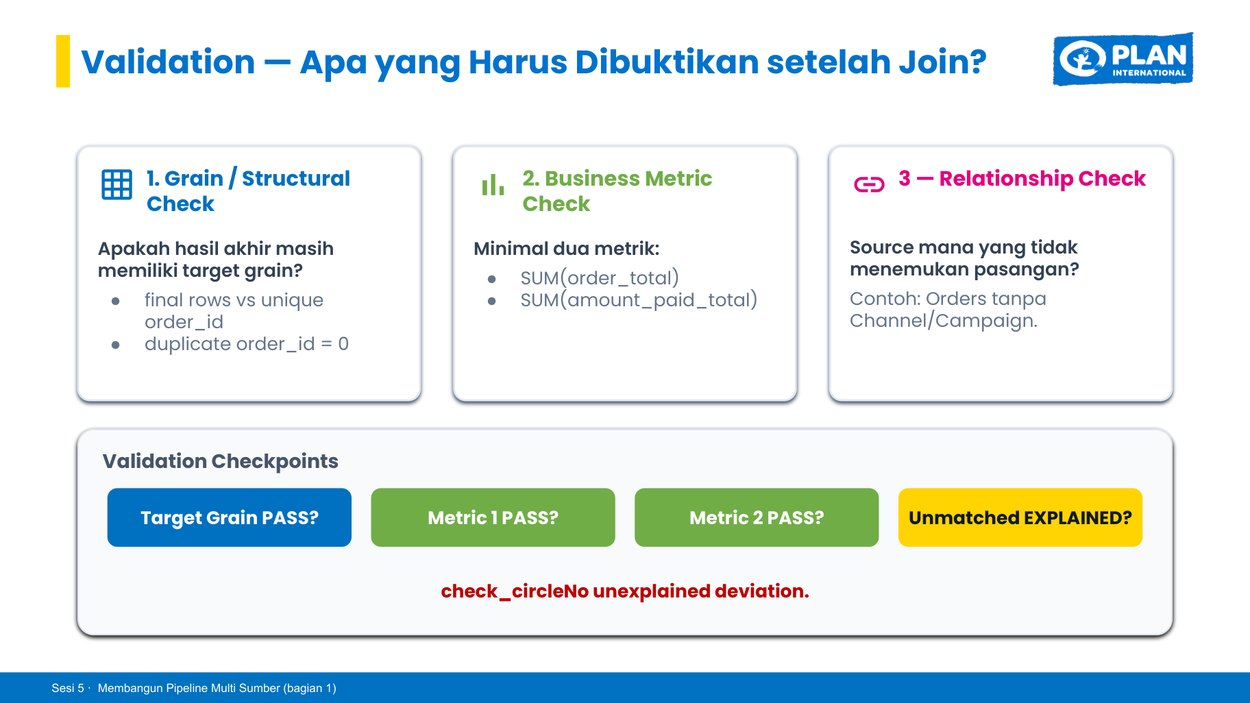

*Empat jenis evidence utama setelah corrected join: grain, dua metrik bisnis, serta unmatched yang dijelaskan. — visual bersumber dari **PPT S5 halaman 24**, bukan screenshot hasil RUN Notebook.*

## Section 9 — Final Validation Gate dan Handoff S6 / Praktik 4

**Jangan menganggap RUN sukses berarti hasil benar.** Lakukan dua kelompok bukti sebelum ekspor:

1. **Lima pemeriksaan utama WP**: grain/jumlah order final, duplicate `order_id`, total Orders, total Payments, dan nilai agregasi Items.
2. **Pemeriksaan hubungan Section 8**: Customers, Items, Payments, Channel/Campaign, dan Source Integrity. Seluruhnya harus `PASS`, kecuali Channel/Campaign boleh `EXPLAINED` jika sesuai bukti source.

**Urutan mengisi WP:** Setelah Section 8, isi `03_Validation_Evidence` **baris 26–30** dahulu. Kemudian jalankan Section 9 dan isi **VE-07 sampai VE-11 (baris 13–17)** berdasarkan tabel check yang tampil.

**Contoh pengisian VE-07:** D13 = 320 (Orders baseline), E13 = jumlah final yang benar-benar muncul, F13 dihitung Excel, G13 = PASS hanya jika keduanya cocok, H13 = `Starter Section 9`.

**Jika HOLD:** Jangan simpan atau kirim hasil join sebagai dataset tervalidasi. Telusuri source/plan/implementasi yang salah, minta Agent memperbaiki **bagian tersebut saja**, lalu ulang Section 7–9.

**Catatan:** Data latihan ini mempunyai **20 unmatched campaign yang diperbolehkan**, tetapi bila mapping yang semestinya tersedia ikut hilang, final gate harus **HOLD**.


In [20]:
import math
from datetime import datetime, timezone
from uuid import uuid4

# SECTION 9 — validasi final dan pengamanan hasil run sebelumnya.
# PENTING: keluaran PASS lama bukan bukti untuk run baru. Sebelum validasi,
# file output sebelumnya dipindahkan ke archive (TIDAK DIHAPUS).
export_names = ["nusamart_integrated_draft_s5.csv",
                "s5_validation_evidence.csv", "s5_relationship_evidence.csv"]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
old_exports = [OUTPUT_DIR / name for name in export_names if (OUTPUT_DIR / name).exists()]
if old_exports:
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    archive_dir = OUTPUT_DIR / "archive" / f"prior_{stamp}_{uuid4().hex[:6]}"
    archive_dir.mkdir(parents=True, exist_ok=False)
    for previous in old_exports:
        previous.replace(archive_dir / previous.name)
    print("PREVIOUS RUN: ARCHIVED — file PASS sebelumnya bukan bukti run terbaru.")
    print("Lokasi arsip:", archive_dir)

pipeline_pass = False
validation_results = None
status_path = OUTPUT_DIR / "s5_run_status.txt"
run_status = "HOLD — validasi belum dapat diterima"
metrics_pass = False
relations_pass = False
sql_payment_pass = False

if final_integrated is None or not globals().get("stage_7d_ready", False):
    print("PIPELINE REVIEW GATE: PENDING/HOLD — selesaikan dan review 7A–7D terlebih dahulu.")
    run_status = "HOLD — corrected pipeline belum lengkap/tervalidasi pada 7D"
elif not JOIN_PLAN_REVIEWED:
    print("PIPELINE REVIEW GATE: HOLD — Join Plan belum disetujui mentor.")
    run_status = "HOLD — Join Plan belum direview"
else:
    needed = {"order_id", "order_total", "amount_paid_total", "item_amount_total", "sales_channel"}
    absent = needed - set(final_integrated.columns)
    if absent:
        print("PIPELINE REVIEW GATE: HOLD — kolom wajib tidak tersedia:", sorted(absent))
        run_status = "HOLD — kolom corrected pipeline tidak lengkap"
    else:
        checks = [
            ("VE-07 | Final rows = baseline Orders", baseline["unique_orders"], len(final_integrated)),
            ("Unique final order_id", baseline["unique_orders"], int(final_integrated["order_id"].nunique())),
            ("VE-08 | Duplicate final order_id", 0, int(final_integrated["order_id"].duplicated().sum())),
            ("VE-09 | SUM(order_total)", baseline["order_total"], float(final_integrated["order_total"].sum())),
            ("VE-10 | SUM(amount_paid_total)", baseline["payment_total"], float(final_integrated["amount_paid_total"].sum())),
            ("VE-11 | SUM(item_amount_total)", float(order_items["line_total"].sum()),
             float(final_integrated["item_amount_total"].sum())),
            ("Number of final columns", 19, len(final_integrated.columns)),
        ]
        validation_results = pd.DataFrame([
            {"Check": label, "Expected": float(expected), "Actual": float(actual),
             "Difference": float(actual) - float(expected),
             "Status": "PASS" if math.isclose(float(expected), float(actual), rel_tol=0, abs_tol=.01) else "FAIL"}
            for label, expected, actual in checks
        ])
        display(validation_results)
        metrics_pass = bool((validation_results["Status"] == "PASS").all())
        relations_pass = bool(globals().get("relationship_evidence") is not None
                              and globals().get("relationship_gate_pass", False))
        print("CORE METRICS:", "PASS" if metrics_pass else "HOLD")
        print("RELATIONSHIP EVIDENCE:", "PASS" if relations_pass else "HOLD / PENDING")

        # Independen dari hasil Agent: query langsung pada sumber SQLite.
        with sqlite3.connect(SOURCE_DIR / "nusamart_payments_s5.sqlite") as db:
            sql_source_payment = pd.read_sql_query(
                "SELECT SUM(amount_paid) AS total_source FROM payments", db)
        sql_expected = float(sql_source_payment.loc[0, "total_source"])
        sql_actual = float(final_integrated["amount_paid_total"].sum())
        sql_payment_pass = math.isclose(sql_expected, sql_actual, rel_tol=0, abs_tol=.01)
        print("INDEPENDENT SQL PAYMENT:", "PASS" if sql_payment_pass else "HOLD")

        if metrics_pass and relations_pass and sql_payment_pass:
            try:
                # Tulis ke file sementara, baru tampilkan file final setelah seluruhnya selesai.
                outputs = [
                    (final_integrated, OUTPUT_DIR / export_names[0]),
                    (validation_results, OUTPUT_DIR / export_names[1]),
                    (relationship_evidence, OUTPUT_DIR / export_names[2]),
                ]
                for frame, path in outputs:
                    temp_path = path.with_suffix(path.suffix + ".tmp")
                    frame.to_csv(temp_path, index=False)
                for _, path in outputs:
                    path.with_suffix(path.suffix + ".tmp").replace(path)
                pipeline_pass = True
                run_status = "PASS — core metrics, relationship, dan SQL independen cocok; export terbaru tersedia"
                print("PIPELINE REVIEW GATE: PASS — hasil terbaru tervalidasi.")
                for _, path in outputs:
                    print("Saved:", path)
                print("Handoff S6: simpan Notebook, Working Paper, dan evidence terbaru.")
            except Exception as exc:
                pipeline_pass = False
                run_status = "HOLD — gagal menyimpan output terbaru"
                for name in export_names:
                    p = OUTPUT_DIR / name
                    tmp = p.with_suffix(p.suffix + ".tmp")
                    if tmp.exists(): tmp.unlink()
                    if p.exists(): p.unlink()  # cegah sebagian output dikira PASS
                print("EXPORT HOLD:", type(exc).__name__, str(exc)[:200])
        else:
            run_status = "HOLD — core, relationship, atau SQL belum lulus"
            print("PIPELINE REVIEW GATE: HOLD — JANGAN gunakan hasil lama / ekspor sebagai PASS.")

status_path.write_text(
    "S5 NusaMart | STATUS RUN TERAKHIR\n" +
    "Waktu UTC: " + datetime.now(timezone.utc).isoformat() + "\n" +
    "Status: " + run_status + "\n" +
    "File PASS lama dipindahkan ke outputs/sesi_05/archive/ setiap Section 9 dijalankan ulang.\n",
    encoding="utf-8"
)
print("LATEST RUN STATUS:", run_status)
print("Bukti status terbaru:", status_path)

,Check,Expected,Actual,Difference,Status
0,VE-07 | Final rows = baseline Orders,320.0,320.0,0.0,PASS
1,Unique final order_id,320.0,320.0,0.0,PASS
2,VE-08 | Duplicate final order_id,0.0,0.0,0.0,PASS
3,VE-09 | SUM(order_total),42061000.0,42061000.0,0.0,PASS
4,VE-10 | SUM(amount_paid_total),42061000.0,42061000.0,0.0,PASS
5,VE-11 | SUM(item_amount_total),42061000.0,42061000.0,0.0,PASS
6,Number of final columns,19.0,19.0,0.0,PASS


CORE METRICS: PASS
RELATIONSHIP EVIDENCE: PASS
INDEPENDENT SQL PAYMENT: PASS
PIPELINE REVIEW GATE: PASS — hasil terbaru tervalidasi.
Saved: C:\Bootcamp\Bootcamp_Data_Analyst\outputs\sesi_05\nusamart_integrated_draft_s5.csv
Saved: C:\Bootcamp\Bootcamp_Data_Analyst\outputs\sesi_05\s5_validation_evidence.csv
Saved: C:\Bootcamp\Bootcamp_Data_Analyst\outputs\sesi_05\s5_relationship_evidence.csv
Handoff S6: simpan Notebook, Working Paper, dan evidence terbaru.
LATEST RUN STATUS: PASS — core metrics, relationship, dan SQL independen cocok; export terbaru tersedia
Bukti status terbaru: C:\Bootcamp\Bootcamp_Data_Analyst\outputs\sesi_05\s5_run_status.txt


### ⏸ STOP 4C — Isi corrected validation (Sheet 03, VE-07–VE-11)

**BACA:** `validation_results` Section 9, lalu pastikan `CORE METRICS`, `RELATIONSHIP EVIDENCE`, dan `INDEPENDENT SQL PAYMENT` semuanya PASS.

| Baris WP | Check | D = Expected | E = Actual |
|---|---|---:|---|
| **13 · VE-07** | Final rows | 320 | `Final rows = baseline Orders` |
| **14 · VE-08** | Duplicate final `order_id` | 0 | `Duplicate final order_id` |
| **15 · VE-09** | SUM(order_total) | 42.061.000 | Hasil final Section 9 |
| **16 · VE-10** | SUM(amount_paid_total) | 42.061.000 | Hasil final Section 9 |
| **17 · VE-11** | Item aggregate reconciles | SUM sumber `order_items.line_total` | Hasil final Section 9 |

**F** = selisih otomatis; **G** = PASS hanya bila selisih 0 dan validasi sesuai; **H**=`Starter Section 9`; **I**=alasan; **J**=perbaikan jika berbeda. Untuk VE-11, **jangan mengarang nominal**: ambil nilai Expected dan Actual dari Section 9.

**CHECKPOINT:** target Sheet 03 = baseline PASS, naive FAIL disengaja, corrected PASS, Fan Trap evidence PASS, unmatched 20 EXPLAINED. **Cek angka sendiri** dan pastikan kolom K menampilkan `OK`; Working Paper terbaru telah memakai pemeriksaan angka otomatis. Namun status `READY` tetap harus dicocokkan dengan output `PIPELINE REVIEW GATE` dari **run Notebook terbaru**, bukan hanya pilihan PASS manual.

**CATAT STATUS RUN TERBARU:** Isi `03_Validation_Evidence!B57` sesuai output Section 9 (`PASS` atau `HOLD`), lalu `D57` dengan lokasi bukti `s5_run_status.txt`. **File untuk handoff S6:** hanya terbit baru jika `PIPELINE REVIEW GATE: PASS`. Lihat `s5_run_status.txt` untuk membedakan hasil terbaru PASS/HOLD; pada HOLD, output PASS lama dipindahkan ke arsip agar tidak salah dianggap run terbaru.

### Verifikasi independen tambahan — bandingkan dengan query SQLite sumber

Untuk membuktikan nilai pembayaran bukan sekadar klaim Agent, jalankan query yang **langsung membaca tabel `payments` di source SQLite**, lalu cocokkan dengan hasil setelah corrected join.

`SELECT SUM(amount_paid) FROM payments` merupakan contoh **SQL Fundamental**. Ini bukan instruksi supaya peserta menyalin seluruh pipeline SQL; kita hanya memeriksa satu angka penting dari sumber berbeda.

**Checkpoint WP setelah Section 9:** isi VE-07–11 di baris 13–17. D adalah `Expected`, E adalah `Actual` dari tabel check di atas. G pilih PASS hanya setelah cocok. **Jangan tertukar dengan VE-04–06 yang berstatus FAIL (expected).**


In [21]:
with sqlite3.connect(SOURCE_DIR / "nusamart_payments_s5.sqlite") as db:
    payment_source_sql = pd.read_sql_query(
        "SELECT COUNT(*) AS payment_rows, SUM(amount_paid) AS payment_total_source FROM payments", db
    )
display(payment_source_sql)
if final_integrated is not None and "amount_paid_total" in final_integrated.columns:
    actual = float(final_integrated["amount_paid_total"].sum())
    expected = float(payment_source_sql.loc[0, "payment_total_source"])
    print("SQL INDEPENDENT PAYMENT CHECK:", "PASS" if math.isclose(expected, actual, abs_tol=0.01) else "FAIL")
else:
    print("SQL PAYMENT BASELINE READY — bandingkan setelah corrected join tersedia.")

,payment_rows,payment_total_source
0,337,42061000


SQL INDEPENDENT PAYMENT CHECK: PASS


---
# PRAKTIK 5 — Apakah analis lain mengerti hasil pipeline kita?

**CASE:** Data NusaMart sudah digabung dan tervalidasi. Analis dashboard bertanya, "Apa arti `amount_paid_total`? Apakah dari Orders atau Payments?" Manajer meminta dokumen agar definisi field tidak hanya diketahui pembuat pipeline.

**TUJUAN:** membuat **draf Data Dictionary** minimal 12 kolom aktual dari hasil pipeline, bukan daftar nama field yang ditebak.

**PAHAMI:** Data Dictionary seperti label produk: memuat nama, arti, sumber, cara menghitung, grain, aturan, serta keterbatasan penggunaan.

**LIHAT CONTOH:** `amount_paid_total` = total nilai `payments.amount_paid` **per order** dari agregasi sebelum final join. Bukan angka hasil menjumlahkan baris naive join.

**JUDGMENT:** jika Section 9 belum PASS, jangan mengesahkan dictionary sebagai hasil dataset valid.

## Section 10 — Draf Data Dictionary | Praktik 5

**COBA:** Setelah `PIPELINE REVIEW GATE: PASS`, jalankan cell berikut dan baca `dictionary_helper` berisi `field_name` serta `actual_dtype`. Tipe data **harus disalin dari output**, bukan diasumsikan.

**BUKA:** `04_Data_Dictionary`, baris 7–36. Dokumentasikan **minimal 12 field yang benar-benar ada** pada `final_integrated`, termasuk key dan beberapa metrik.

| Kolom Sheet 04 | Isi | Di mana sumbernya? |
|---|---|---|
| **A** | Nama field **persis** | `dictionary_helper.field_name` |
| **B** | Tipe data aktual | `dictionary_helper.actual_dtype` |
| **C** | Arti kolom dalam bisnis NusaMart | Interpretasi setelah melihat sample output |
| **D** | Sumber / rumus pembentuk | Orders/Customers/Products/Payments/Campaign dan Section 7A–7D |
| **E** | Grain akhir | `1 row = 1 order` |
| **F** | Key / constraint | `order_id` unik; catatan bila berlaku |
| **G** | Jika metrik, cara hitung | Mis. `SUM(payments.amount_paid) per order_id` |
| **H** | Caveat/batasan | Mis. 20 order tanpa mapping campaign |
| **I** | Status | `DRAFTED` **setelah dicek** |

**CONTOH SATU BARIS (bukan urutan wajib):** A=`amount_paid_total`, B=**dtype aktual Section 10**, C=`Total pembayaran per order`, D=`SUM(payments.amount_paid) per order_id`, E=`1 row = 1 order`, F=`Metrik per order_id`, G=`SUM(amount_paid) per order`, H=`Dihitung sebelum final join supaya tidak terduplikasi`, I=`DRAFTED` setelah review.

**Prompt opsional Antigravity:**
```text
Gunakan daftar dictionary_helper dan kode aktual Section 7A–7D, bukan
tebakan. Untuk setiap field yang benar-benar muncul di final_integrated,
jelaskan arti bisnis, source/derivation, grain, key/constraint, rumus jika
metrik, dan batasan. Jangan mengarang field atau datatype. Saya akan
memeriksa sebelum mengisi Sheet 04.
```

**PENTING:** Ini **DRAF**, finalisasi baru pada S6. Jangan menyebutnya dokumentasi final.

In [22]:
if final_integrated is None or not globals().get("pipeline_pass", False):
    print("DATA DICTIONARY: HOLD/PENDING — Section 9 belum PASS. Perbaiki pipeline/validation dahulu.")
else:
    dictionary_helper = pd.DataFrame({
        "field_name": final_integrated.columns,
        "actual_dtype": [str(t) for t in final_integrated.dtypes],
    })
    display(dictionary_helper)
    print("Jumlah field aktual:", len(dictionary_helper))
    print("Isi 04_Data_Dictionary berdasarkan output, bukan menebak datatype.")

# Ubah TRUE hanya SETELAH Working Paper 04 selesai diperiksa.
DATA_DICTIONARY_DRAFTED = True
print("DATA DICTIONARY STATUS:", "REVIEWED" if DATA_DICTIONARY_DRAFTED else "PENDING — lengkapi WP 04 dahulu")

,field_name,actual_dtype
0,order_id,str
1,customer_id,str
2,order_date,str
3,order_status,str
4,order_total,int64
5,city_group,str
6,customer_segment,str
7,join_date,str
8,customer_status,str
9,item_count,int64


Jumlah field aktual: 19
Isi 04_Data_Dictionary berdasarkan output, bukan menebak datatype.
DATA DICTIONARY STATUS: REVIEWED


### ⏸ STOP 5A — Lengkapi Data Dictionary lalu review

**BACA** seluruh `dictionary_helper`, pilih **minimal 12 field aktual** dari hasil Section 10. Kamu boleh memulai dari `order_id`, `order_total`, `amount_paid_total`, atau `unique_category_count` **hanya jika muncul di output**.

**ISI** Sheet `04_Data_Dictionary` **baris 7–36**, kolom A–H dari evidence aktual; I=`DRAFTED` setelah sumber/rumus dan makna dicek. Untuk dtype, **copy isi `actual_dtype`**, jangan mengetik `int`/`float` dari perkiraan.

**Pertanyaan mentor:** Apa bedanya `order_total` dan `amount_paid_total`? Mengapa 20 campaign yang tidak match perlu dijelaskan pada caveat? Bagaimana rumus `unique_category_count` ditelusuri dari Products?

**CHECKPOINT:** minimal 12 baris DRAFTED, provenance dan formula metrik dapat ditelusuri, barulah ubah `DATA_DICTIONARY_DRAFTED = True` setelah di-review. `dictionary_helper` adalah penolong, bukan pengganti Working Paper.

**KESIMPULAN S5:** keenam source bisa digabungkan secara terkontrol dan dijelaskan. Ke S6: uji apakah orang lain dapat menjalankan pipeline yang sama dari kondisi bersih (*reproducibility*).

## Penutup — Dua output resmi, satu keputusan analitis

**Output resmi 1: Draf Pipeline Penggabungan 6 Sumber** → Notebook ini telah berisi implementasi nyata 7A–7D yang kamu review, Section 8–9 menunjukkan hasil validasi PASS, dan ada data integrasi serta evidence pendukung. **CSV saja bukan pipeline**.

**Output resmi 2: Draf Data Dictionary** → Sheet `04_Data_Dictionary` berisi minimal 12 field aktual, arti bisnis, derivasi, grain, serta caveat. **Belum final sampai S6**.

### Checklist handoff
- `01_Source_Inventory` baris 7–12 terisi dan key `REVIEWED` sesuai evidence.
- `02_Join_Plan` JP-01–JP-05 direview **sebelum** kode 7A–7D dibuat.
- `03_Validation_Evidence`: baseline PASS, naive FAIL (sengaja), investigasi fan trap PASS, corrected PASS, 20 unmatched channel EXPLAINED.
- `04_Data_Dictionary`: minimal 12 field aktual berstatus DRAFTED dan asal/rumsunya diketahui.
- Pada Notebook: 7A–7D benar-benar berupa kode yang ditinjau dan `PIPELINE REVIEW GATE: PASS` pada run terbaru.
- Simpan Notebook dan Working Paper. File `outputs/sesi_05/` adalah bukti pendukung; cek **`s5_run_status.txt`** agar tidak salah memakai hasil PASS lama saat run terbaru HOLD.

### Troubleshooting ringan
| Pesan | Makna | Tindakan |
|---|---|---|
| `SOURCE FOLDER: NOT FOUND` | Folder latihan tidak ditemukan | Benahi folder source / `SOURCE_DIR_OVERRIDE` |
| `SOURCE FILE CHECK: HOLD` | Ada file yang belum tersedia | Cek nama dan lokasi enam file S5 |
| `7A/7B/7C/7D PENDING` | TODO praktik Antigravity belum dikerjakan | Selesaikan satu bagian lalu review output |
| `7D HOLD` | Join Plan/bagian sebelumnya belum lulus | Kembali ke tahap yang bermasalah |
| `RELATIONSHIP REVIEW: HOLD` | Hubungan/mapping tidak sesuai evidence | Telusuri Section 8 dan Join Plan |
| `PIPELINE REVIEW GATE: HOLD` | Belum layak untuk ekspor terbaru | Baca check yang gagal, perbaiki kode; jangan pilih PASS manual |
| `LOCAL FALLBACK` | Tidak memakai data Google Sheets live | Cantumkan fallback secara jujur pada Sheet 01 |

### Refleksi akhir (diskusi singkat bersama mentor)
1. Apa bukti bahwa naive join menghasilkan laporan yang menyesatkan?
2. Keputusan apa yang harus manusia buat **sebelum** meminta Antigravity menulis kode?
3. Mengapa hasil corrected join baru dapat dipercaya setelah metric, relationship, dan SQL independen cocok?

**Dibawa ke S6:** Notebook S5, Working Paper S5, Join Plan, baseline, dictionary draft, dan evidence dari run terbaru. Jangan menyebut pipeline S5 "100% reproducible" sebelum clean rebuild dan peer test S6.

## Jawab

1. Buktinya, jumlah baris meningkat dari 320 menjadi 802, total order dari Rp42.061.000 menjadi Rp109.177.000, dan total pembayaran menjadi Rp103.431.000. Hal ini terjadi karena orders, order_items, dan payments digabung langsung sehingga beberapa nilai terhitung berulang (fan-trap). Akibatnya, laporan menunjukkan nilai transaksi yang lebih besar daripada kondisi sebenarnya.

2. Manusia harus menentukan tujuan analisis, grain data (1 baris = 1 order), primary key dan join key, hubungan antar tabel, serta cara menangani data yang tidak memiliki pasangan (unmatched). Selain itu, manusia harus menentukan aturan agregasi, perlindungan data pelanggan, dan kriteria validasi agar kode yang dibuat sesuai kebutuhan.

3. Karena ketiganya memeriksa hasil dari sisi berbeda. Metric memastikan jumlah baris dan total nilai sesuai baseline, relationship memastikan hubungan antar tabel benar dan tidak ada duplikasi atau unmatched yang tidak diharapkan, sedangkan SQL independen memverifikasi hasil menggunakan perhitungan terpisah dari kode Antigravity. Jika ketiganya cocok, hasil corrected join memiliki bukti yang lebih kuat bahwa data telah digabung dengan benar dan tidak mengalami penggandaan nilai.